# Housing Price Prediction Model

## Objective

The objective of this project is to perform a complete analysis of residential
housing data and develop a robust machine learning model to predict the sale
price of a house based on its various characteristics.

The project also aims to:

1. Understand the important factors affecting house prices.
2. Analyze the relationship between house features and SalePrice.
3. Compare multiple machine learning regression models.
4. Select the best-performing model for house price prediction.
5. Provide useful suggestions to customers based on house characteristics,
   location and price.

##  Dataset Description

The dataset contains information about residential properties in Ames, Iowa.

The dataset was compiled by Dean De Cock and contains residential property sales information from Ames, Iowa. It is widely used for demonstrating regression, feature engineering, and machine-learning techniques for house-price prediction.

The dataset contains information related to different aspects of a house,
including:

- Property size and area
- Building class and zoning
- Location and neighborhood
- Overall material and finish quality
- Overall condition
- Construction and remodeling year
- Basement characteristics
- Living area
- Number of bedrooms and bathrooms
- Kitchen quality
- Garage characteristics
- Outdoor features
- Sale information

The target variable is SalePrice, which represents the property's sale price
in dollars.

## WorkFlow
1. Import Libraries
2. Load Dataset
3. Understand Dataset
4. Data Cleaning
5. Exploratory Data Analysis (EDA)
6. Univariate Analysis
7. Bivariate Analysis
8. Feature–SalePrice Relationships
9. Feature Engineering
10. Prepare Data for ML
11. Train/Test Split
12. Model Building
13. Model Comparison
14. Hyperparameter Tuning
15. Final Model Selection
16. Prediction Testing
17. Feature Importance
18. Customer Recommendations
19. Challenges Faced + Solutions
20. Final Conclusion

## Introduction

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import time

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor 

import warnings 
warnings.filterwarnings("ignore")

## Loading the Dataset

In [2]:
df=pd.read_csv("PRCP-1020-HousePricePred.zip1/data.csv")
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


## Initial Data Exploration

Before performing data cleaning and exploratory data analysis, the dataset
is inspected to understand its dimensions, structure, data types and
statistical characteristics.

In [3]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [5]:
df.sample()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
573,574,80,RL,76.0,9967,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,170000


In [6]:
df.size

118260

In [7]:
df.shape

(1460, 81)

In [8]:
df.columns.tolist()

['Id',
 'MSSubClass',
 'MSZoning',
 'LotFrontage',
 'LotArea',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'MasVnrArea',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinSF1',
 'BsmtFinType2',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'KitchenQual',
 'TotRmsAbvGrd',
 'Functional',
 'Fireplaces',
 'FireplaceQu',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageCars',
 'GarageArea',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'WoodDeckSF',
 'OpenPorchSF'

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [11]:
df.dtypes.value_counts()

object     43
int64      35
float64     3
Name: count, dtype: int64

### Data Type Analysis

The dataset contains both numerical and categorical variables.

Numerical variables represent measurable quantities such as area, number of
rooms, year of construction and sale price.

Categorical variables represent descriptive characteristics such as
neighborhood, zoning, house style, quality and type of facilities.

### Target Variable Analysis


SalePrice is the target variable of the project.

It represents the final sale price of each residential property in dollars.

Understanding the distribution of SalePrice is important before developing
the machine learning models because the target distribution can influence
model performance and the choice of preprocessing techniques.

In [12]:
df['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [13]:
# check skewness and kurtosis
print("SalePrice Skewness:", df['SalePrice'].skew())
print("SalePrice Kurtosis:", df['SalePrice'].kurt())

SalePrice Skewness: 1.8828757597682129
SalePrice Kurtosis: 6.536281860064529


### SalePrice Distribution 

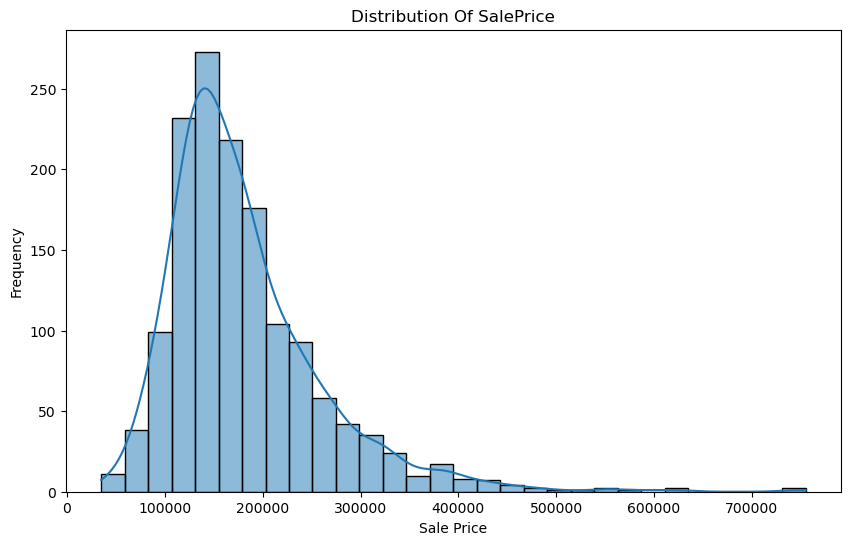

In [14]:
plt.figure(figsize=(10,6))
sns.histplot(df['SalePrice'], bins=30, kde=True)

plt.title("Distribution Of SalePrice")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

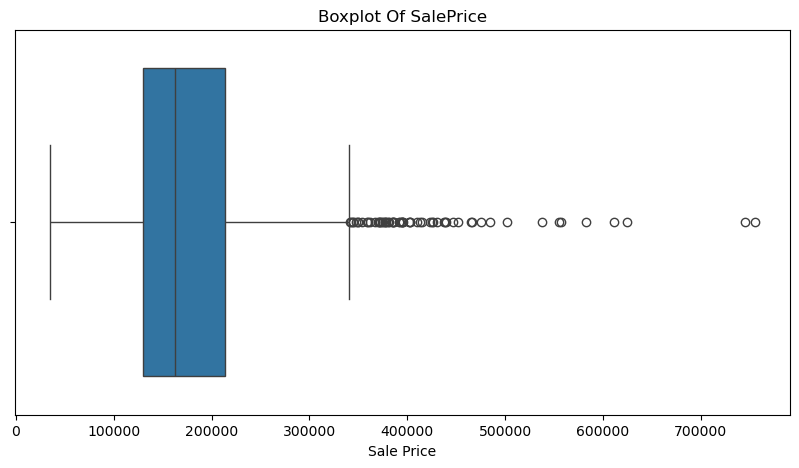

In [15]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['SalePrice'])

plt.title("Boxplot Of SalePrice")
plt.xlabel("Sale Price")
plt.show()

- SalePrice was positively skewed. Although log transformation is commonly used for house-price regression, the project retained the original target scale because the primary final model was Gradient Boosting and the evaluation metrics were required in the original dollar scale.

## Data Cleaning

In [16]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

### Missing value Analysis

In [18]:
missing = df.isnull().sum().sort_values(ascending=False)

missing_df = pd.DataFrame({
    'Missing_Count': missing,
    'Missing_Percentage': (missing / len(df)) * 100
})

missing_df[missing_df['Missing_Count'] > 0]

,Missing_Count,Missing_Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageYrBlt,81,5.547945
GarageCond,81,5.547945
GarageType,81,5.547945


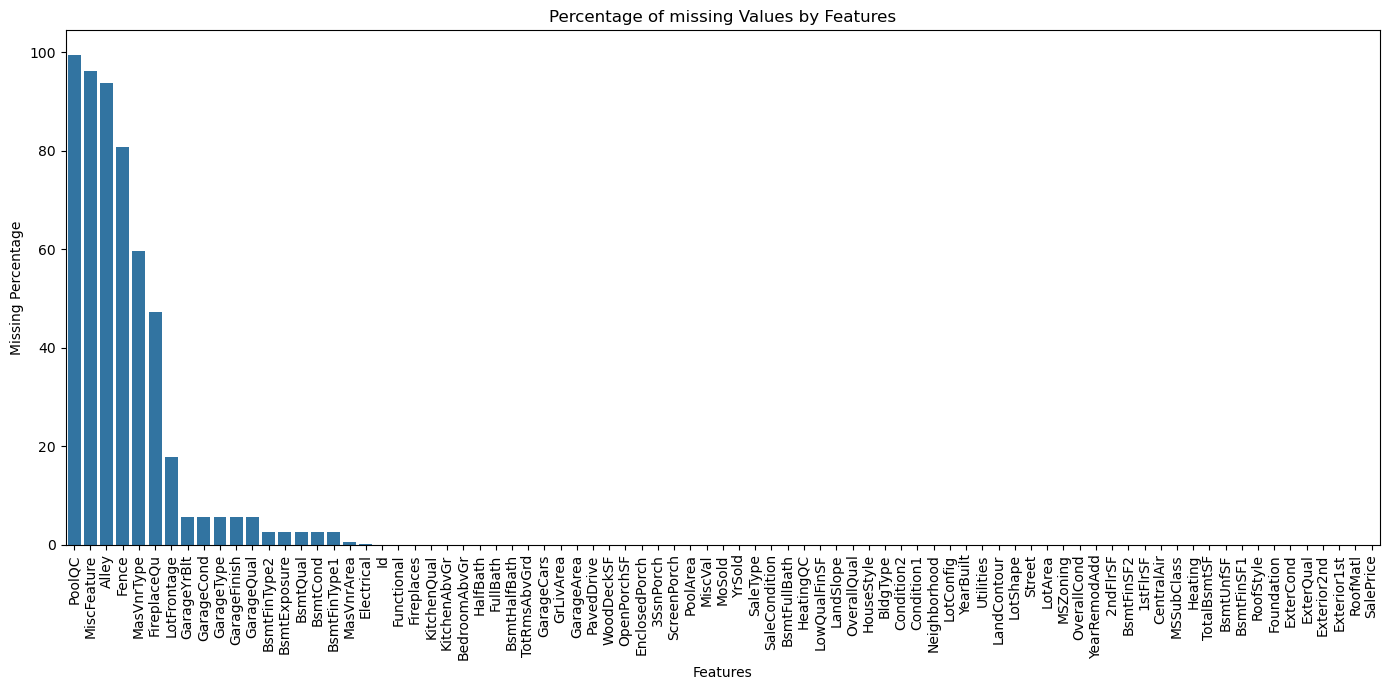

In [19]:
plt.figure(figsize=(14,7))

sns.barplot(x=missing_df.index, 
           y=missing_df["Missing_Percentage"] )

plt.title("Percentage of missing Values by Features")
plt.xlabel('Features')
plt.ylabel('Missing Percentage')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [20]:
# checking target Missing Values
print('Missing SalePrice Values:', df["SalePrice"].isnull().sum())

Missing SalePrice Values: 0


In [21]:
# checking Id
print(df['Id'].head())
print("\nNumber of unique IDs:", df["Id"].nunique())
print("Number of Rows:", len(df))

0    1
1    2
2    3
3    4
4    5
Name: Id, dtype: int64

Number of unique IDs: 1460
Number of Rows: 1460


### Analysis(Data cleaning)

The dataset contains missing values in several features. The missing values
were not treated uniformly because their meaning differs across variables.

For property-related categorical features such as pool, fence, alley,
fireplace, garage and basement characteristics, a missing value can indicate
that the corresponding feature is not present in the property.

For numerical variables and genuinely unknown categorical values, appropriate
imputation techniques were applied.

This approach prevents the loss of useful observations and preserves the
meaning of the original housing data.

### ---Handle Features that are Absent---

In [22]:
none_cols = [
    'PoolQC',
    'MiscFeature',
    'Alley',
    'Fence',
    'MasVnrType',
    'FireplaceQu',
    'GarageQual',
    'GarageFinish',
    'GarageType',
    'GarageCond',
    'BsmtFinType2',
    'BsmtExposure',
    'BsmtCond',
    'BsmtQual',
    'BsmtFinType1'
]

df[none_cols] = df[none_cols].fillna('None')

In [23]:
# --- Handle GarageYrBlt ---

# The missing values in GarageYrBlt correspond to properties without a garage.
# Therefore, the missing values were replaced with 0 to represent the absence
# of a garage rather than estimating a garage construction year where no garage
# exists.


df['GarageYrBlt']= df['GarageYrBlt'].fillna(0)

In [24]:
# --- Handle MasVnrArea ---

# Missing values in MasVnrArea were replaced with 0. A value of 0 represents
# the absence of masonry veneer area and is consistent with the existing
# representation of properties without masonry veneer.


df['MasVnrArea']=df['MasVnrArea'].fillna(0)

In [25]:
# --- Handle Electrical ---

# Only one observation contains a missing Electrical value. Since Electrical
# is a categorical variable and the number of missing observations is extremely
# small, the missing value was replaced using the mode of the feature.


# df['Electrical']= df['Electrical'].fillna(
#     df['Electrical'].mode()[0] )

In [26]:
# --- Handle LotFrontage --- 

# LotFrontage contains a relatively large number of missing observations.
# Instead of using the overall dataset median, missing values were imputed
# using the median LotFrontage of the corresponding Neighborhood.

# Neighborhood-wise median imputation was selected because properties within
# the same neighborhood are more likely to have similar lot characteristics.



# df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(
#     lambda x : x.fillna(x.median())
# )

In [27]:
# --- Verify missing values---

missing_after_cleaning = df.isnull().sum()

display(
    missing_after_cleaning[missing_after_cleaning >0
        ]
)

LotFrontage    259
Electrical       1
dtype: int64

In [28]:
print('Total missing values after cleaning:',
     df.isnull().sum().sum()
     )

Total missing values after cleaning: 260


In [29]:
# --- Verify duplicates again ---

print("Duplicatte rows:", df.duplicated().sum())

Duplicatte rows: 0


In [30]:
print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (1460, 81)


### Data Cleaning Summary

The following data-cleaning techniques were applied:

1. Missing values in property-related categorical variables were replaced
   with "None" when the missing value represented the absence of that feature.

2. Missing GarageYrBlt values were replaced with 0 because the corresponding
   properties did not have a garage.

3. Missing MasVnrArea values were replaced with 0.

4. The single missing Electrical value was replaced using the mode.

5. Missing LotFrontage values were imputed using the median LotFrontage
   within the corresponding Neighborhood.

6. Duplicate records were checked and no duplicate rows were found.

After cleaning, the dataset contains no missing values and all 1,460
observations have been retained.

# Exploratory Data Analysis

Now that the dataset is cleaned, we can investigate which house characteristics are most strongly associated with SalePrice. The project specifically requires determining the relationship between house features and price.

## Numerical Feature Distribution

-The numerical features were analyzed using histograms to understand their distribution, spread, skewness, and presence of unusually large or small observations. This analysis helps identify variables that may require transformation or further investigation before model development.

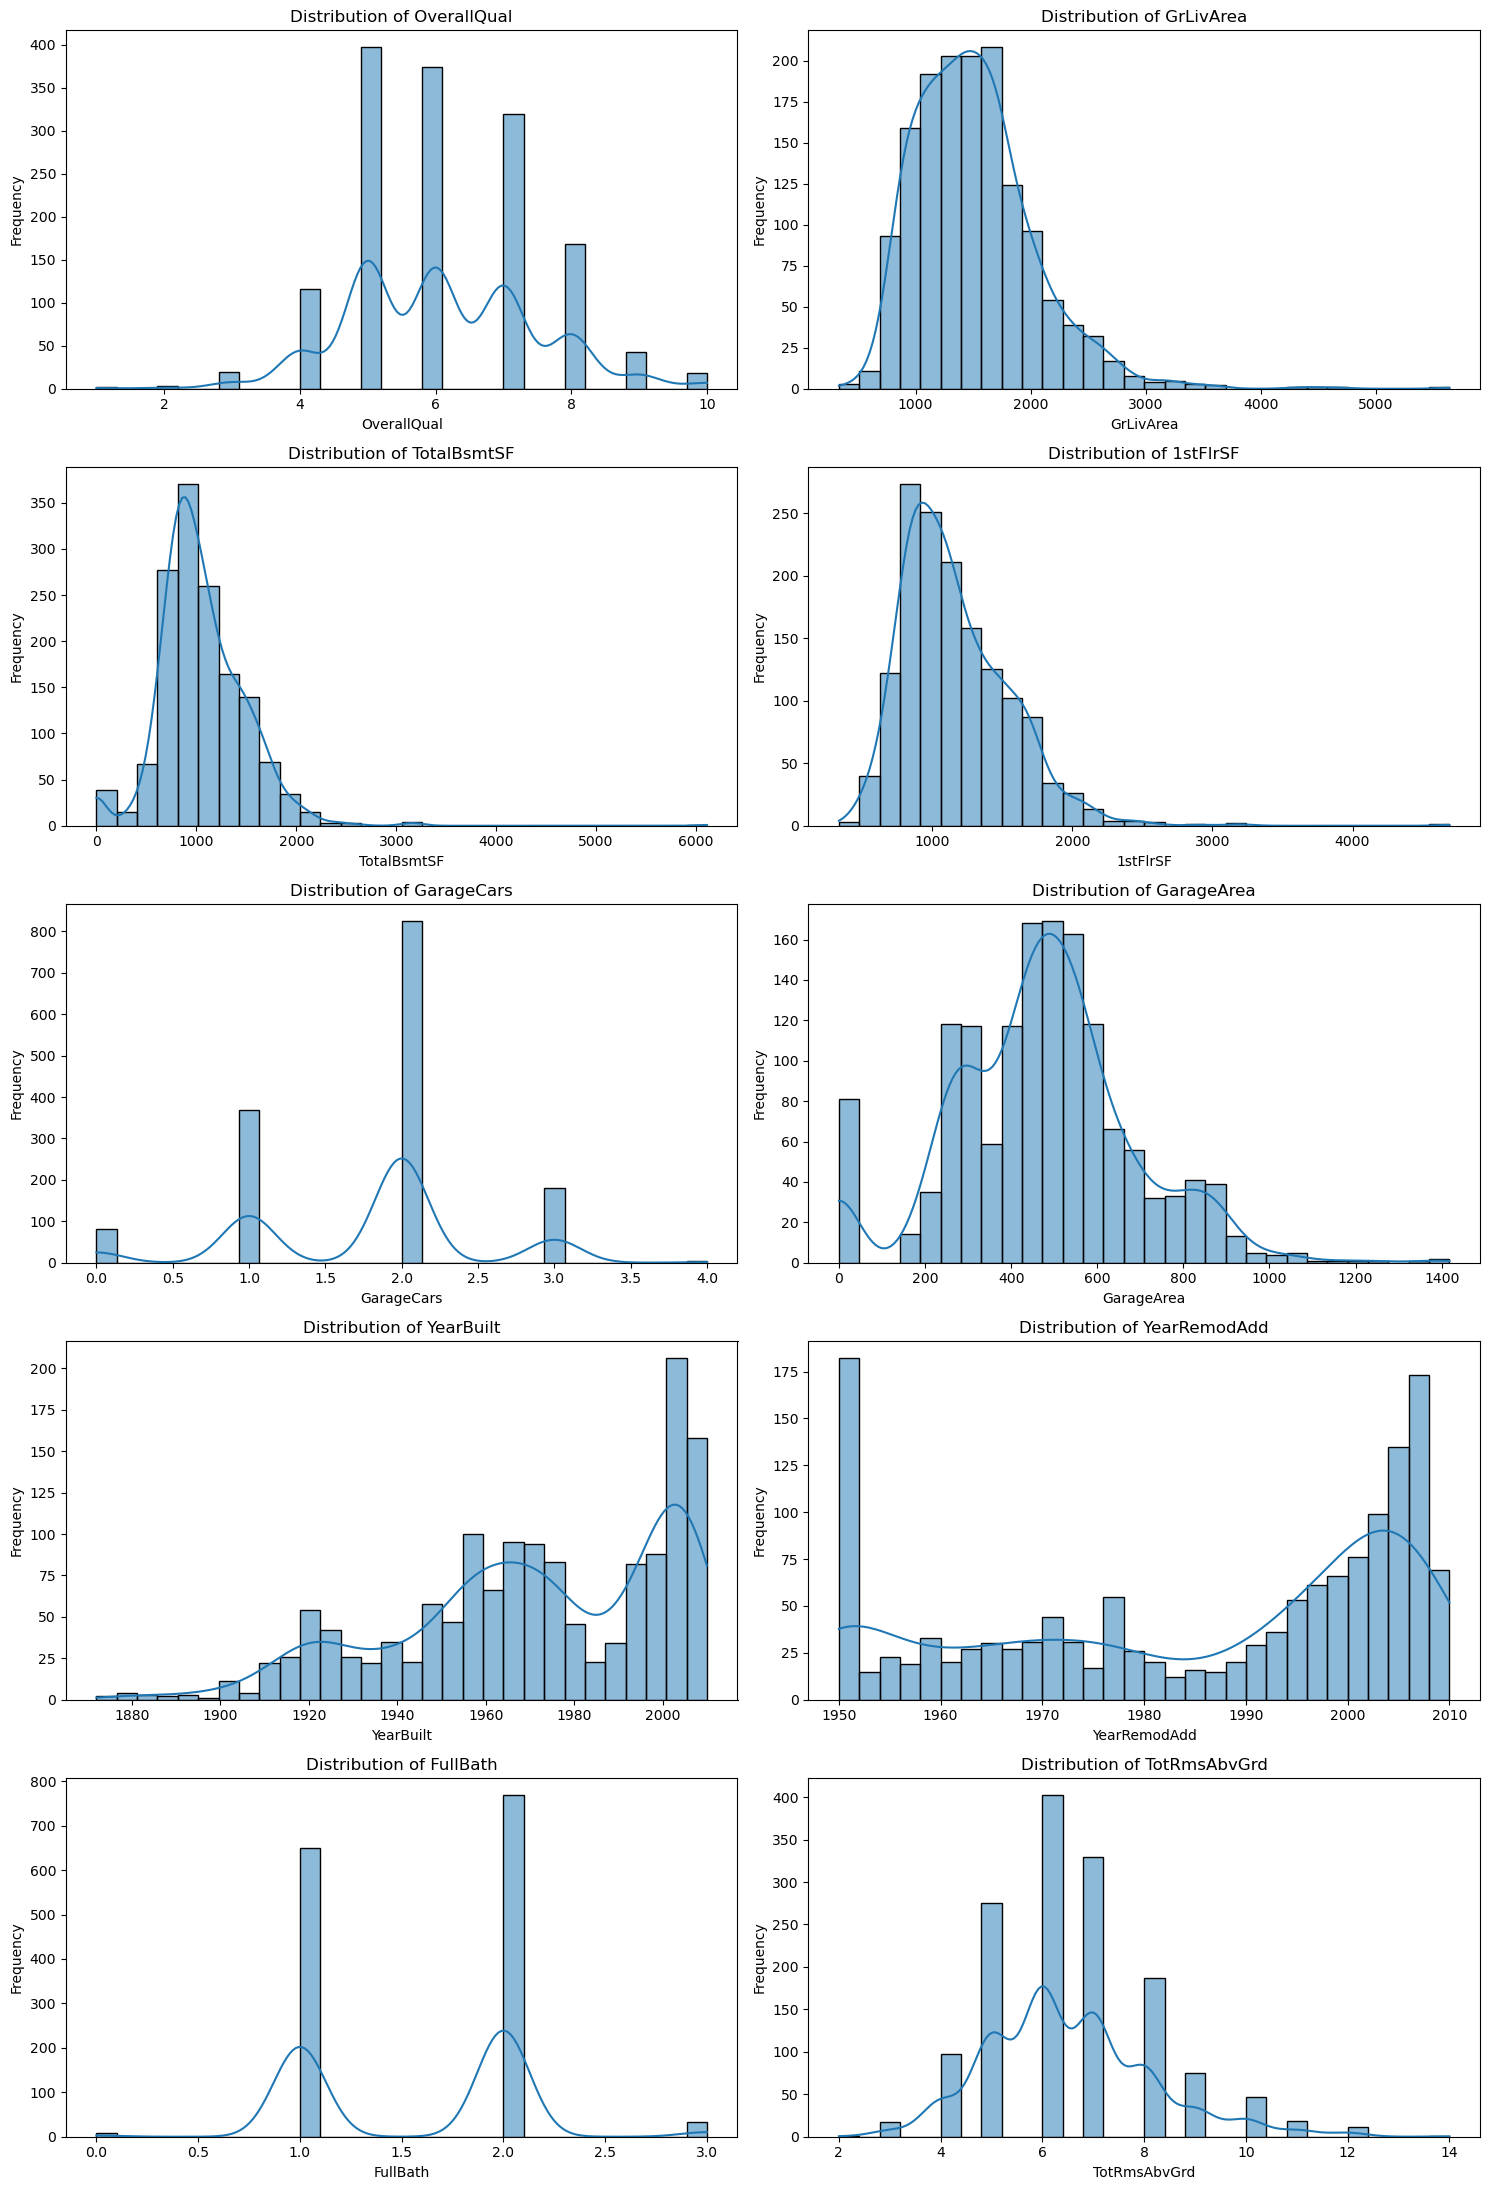

In [31]:
# Important Numerical Features for Distribution analysis 

important_numerical_features = [
    'OverallQual',
    'GrLivArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'GarageCars',
    'GarageArea',
    'YearBuilt',
    'YearRemodAdd',
    'FullBath',
    'TotRmsAbvGrd'
]

fig, axes = plt.subplots(5,2, figsize=(15,22))

for ax, feature in zip(axes.flatten(), important_numerical_features):
    sns.histplot(df[feature],bins=30, kde=True , ax=ax)
    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

- OverallQual contains a relatively limited number of quality ratings.
- GrLivArea represents above-ground living area and has a wider numerical range.
- TotalBsmtSF and 1stFlrSF measure important components of house size.
- YearBuilt and YearRemodAdd represent construction/remodeling years.
- GarageCars represents garage capacity.
- Several area-related variables are right-skewed.

This gives us an initial indication that house size, quality, age and facilities may be important price-related factors.

### Correlation Analysis
- Correlation analysis was performed to identify numerical features that have a strong linear relationship with the target variable, SalePrice. This helps in understanding the important predictors and provides guidance for subsequent feature selection and modeling.

In [32]:
numerical_df = df.select_dtypes(include=['int64','float64'])

correlation_matrix = numerical_df.corr()

SalePrice_correlation = (
    correlation_matrix['SalePrice'].sort_values(ascending=False)
)
display(SalePrice_correlation)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
GarageYrBlt      0.261366
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

### Top Features Correlated with SalePrice

In [33]:
# Top 15 numerical features correlated with SalePrice

top_correlations = (
    SalePrice_correlation.drop('SalePrice').sort_values(ascending=False).head(15)
)
display(top_correlations.to_frame(name= 'Correlation with SalePrice'))

,Correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


### Correlation Heatmap

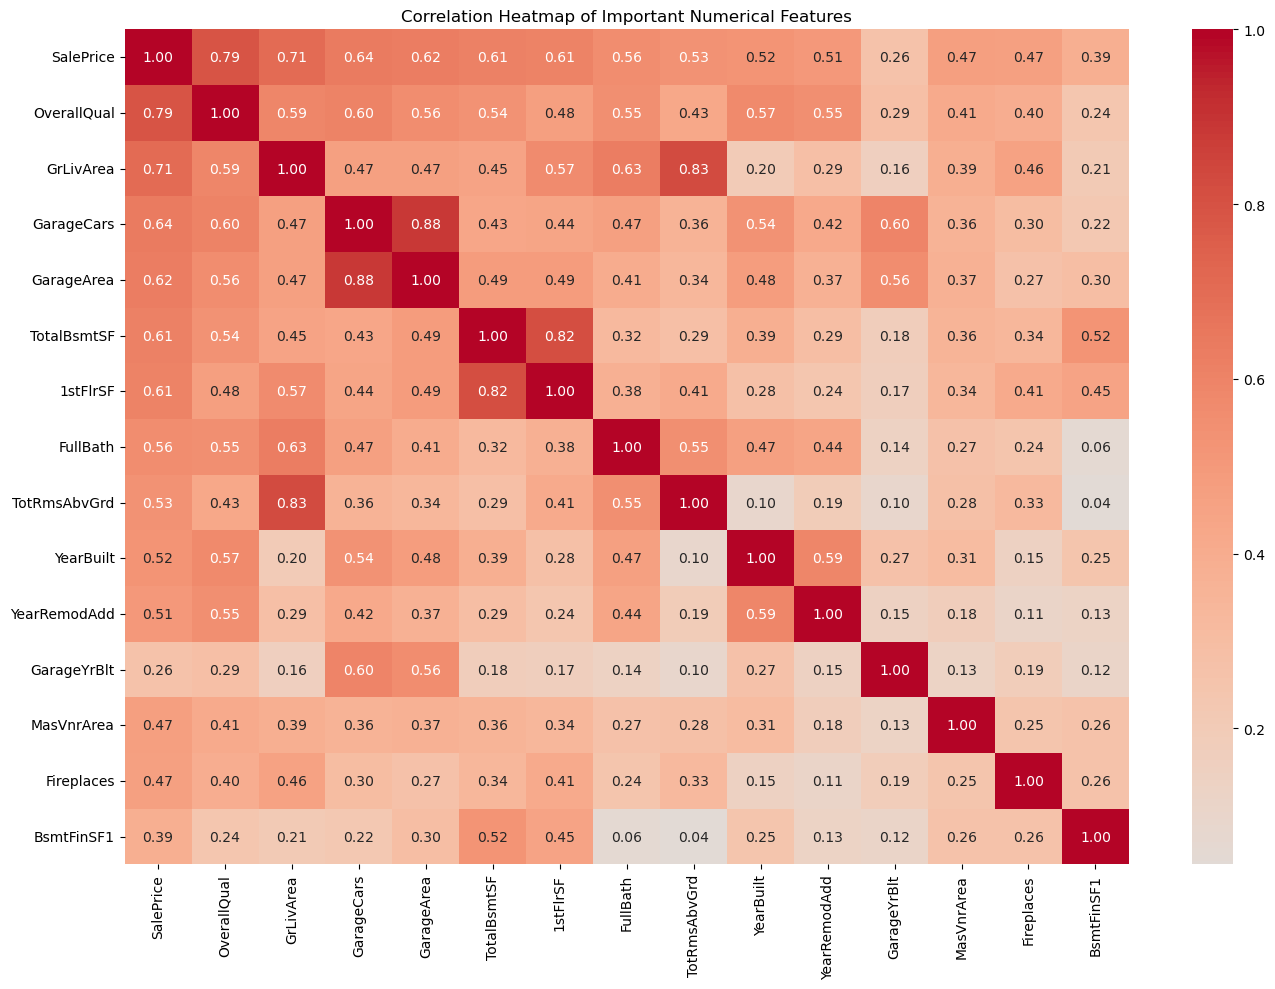

In [34]:
# Select top correlated numerical features
top_features = [
     'SalePrice',
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'GarageArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'FullBath',
    'TotRmsAbvGrd',
    'YearBuilt',
    'YearRemodAdd',
    'GarageYrBlt',
    'MasVnrArea',
    'Fireplaces',
    'BsmtFinSF1'
]

plt.figure(figsize=(14,10))
sns.heatmap(df[top_features].corr(),
           annot=True, fmt=".2f", cmap= 'coolwarm', center=0)
plt.title('Correlation Heatmap of Important Numerical Features')
plt.tight_layout()
plt.show()

###  OverallQual vs SalePrice

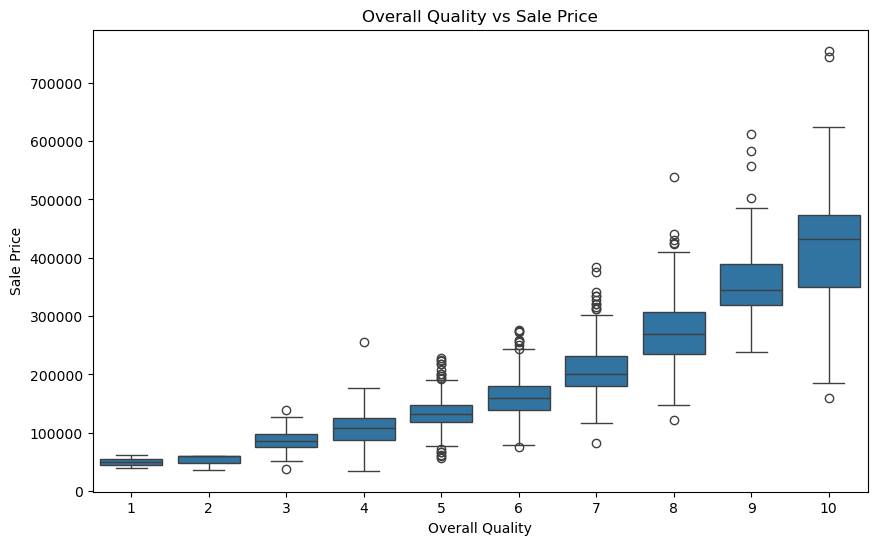

In [35]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x='OverallQual',
    y='SalePrice',
    data=df
)

plt.title('Overall Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()

### GrLivArea vs SalePrice

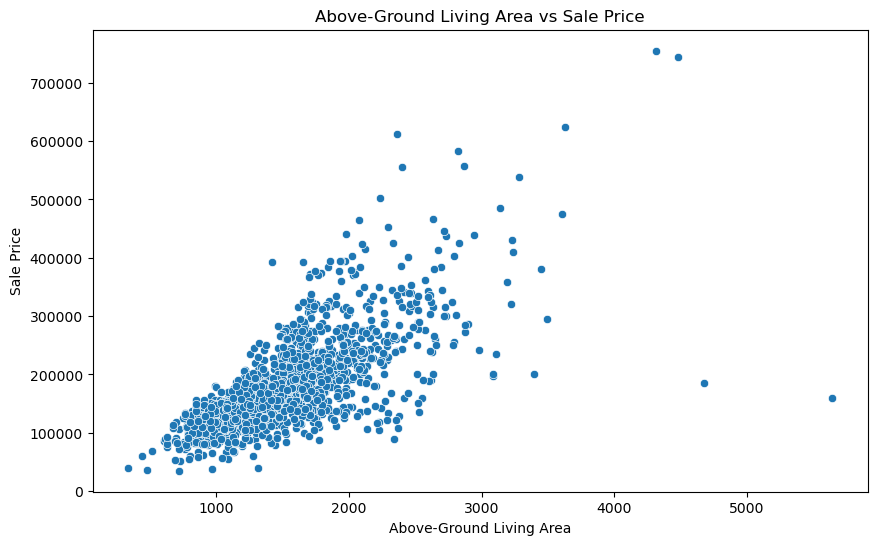

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='GrLivArea',
    y='SalePrice',
    data=df
)

plt.title('Above-Ground Living Area vs Sale Price')
plt.xlabel('Above-Ground Living Area')
plt.ylabel('Sale Price')

plt.show()

### YearBuilt vs SalePrice

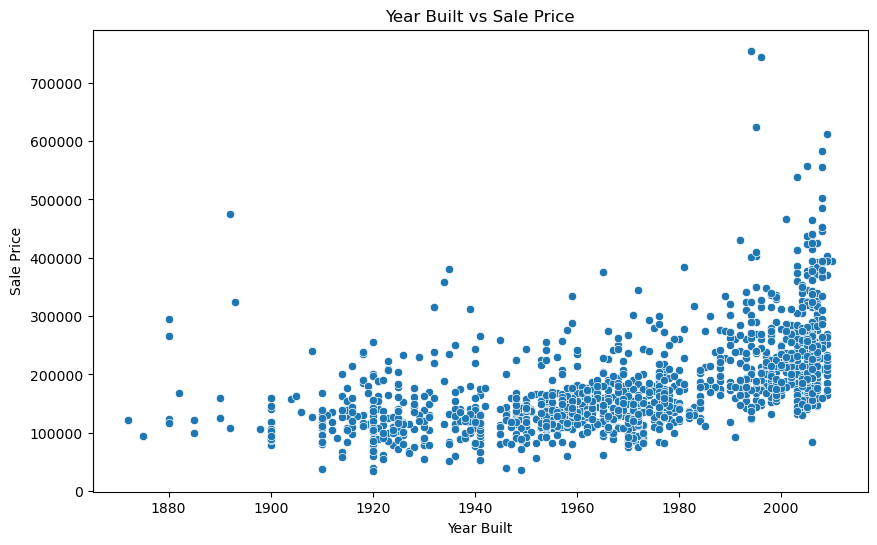

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='YearBuilt',
    y='SalePrice',
    data=df
)

plt.title('Year Built vs Sale Price')
plt.xlabel('Year Built')
plt.ylabel('Sale Price')

plt.show()

### TotalBsmtSF vs SalePrice

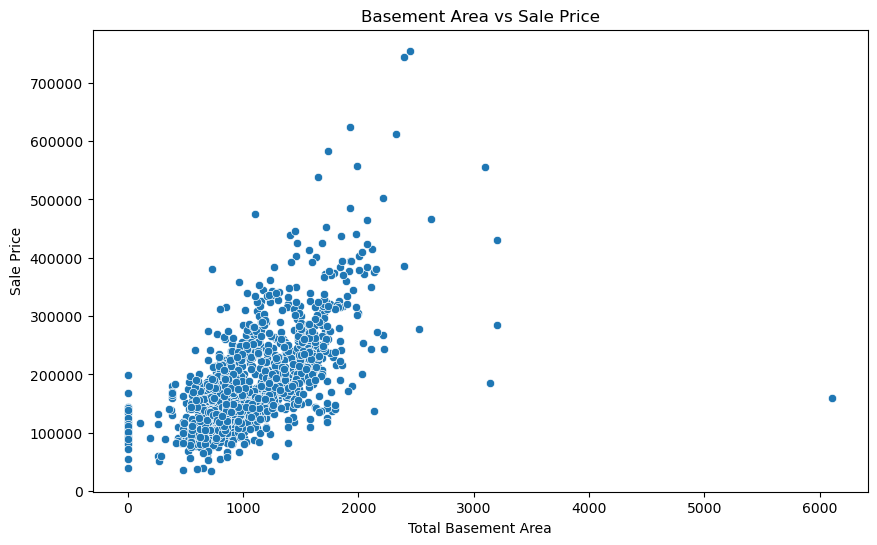

In [38]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='TotalBsmtSF',
    y='SalePrice',
    data=df
)

plt.title('Basement Area vs Sale Price')
plt.xlabel('Total Basement Area')
plt.ylabel('Sale Price')

plt.show()

### GarageCars vs SalePrice

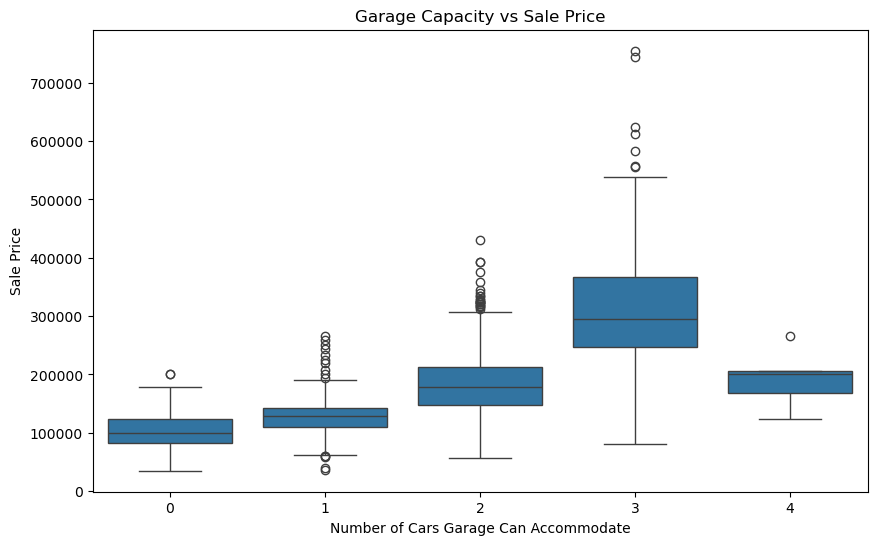

In [39]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x='GarageCars',
    y='SalePrice',
    data=df
)

plt.title('Garage Capacity vs Sale Price')
plt.xlabel('Number of Cars Garage Can Accommodate')
plt.ylabel('Sale Price')

plt.show()

### Key Findings from Numerical EDA

The numerical exploratory analysis provided several important observations:

1. Correlation was used as an initial exploratory measure of linear association. Final feature usefulness was assessed through model performance and feature importance rather than correlation alone.

2. GrLivArea also showed a strong positive relationship with SalePrice, suggesting that larger above-ground living areas generally command higher prices.

3. GarageCars, GarageArea, TotalBsmtSF and 1stFlrSF showed substantial positive relationships with SalePrice.

4. FullBath and TotRmsAbvGrd also showed positive relationships with the target.

5. YearBuilt and YearRemodAdd showed positive relationships with SalePrice, indicating that newer construction and recent remodeling are generally associated with higher prices.

6. Some predictor variables are strongly correlated with each other. This indicates possible overlapping information between features and should be considered during model development.

7. Several area-related variables contain potentially extreme observations. These observations will be investigated rather than automatically removed so that legitimate high-value properties are not incorrectly discarded.

Overall, the EDA indicates that house quality, living area, size, garage facilities, basement area and construction characteristics are important factors associated with house prices.

## Categorical Feature Analysis


The dataset contains several categorical variables describing qualitative characteristics of residential properties. These include neighborhood, zoning, exterior quality, kitchen quality, basement quality, garage finish and other property characteristics.

Categorical feature analysis was performed to understand how different categories are associated with SalePrice.

In [40]:
#  Identify Categorical columns

categorical_columns = df.select_dtypes(include=['object']).columns

print("Number of categorical features:", len(categorical_columns))
print("\nCategorical features:")
print(categorical_columns.tolist())

Number of categorical features: 43

Categorical features:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [41]:
# ---- Number of unique Categories ----

categorical_summary = pd.DataFrame({
    'Feature': categorical_columns, 
    'Unique_Categories': [df[col].nunique()for col in categorical_columns]
})
categorical_summary = categorical_summary.sort_values(
    by='Unique_Categories',ascending=False
)
display(categorical_summary)

,Feature,Unique_Categories
8,Neighborhood,25
16,Exterior2nd,16
15,Exterior1st,15
41,SaleType,9
9,Condition1,9
14,RoofMatl,8
10,Condition2,8
12,HouseStyle,8
25,BsmtFinType2,7
31,Functional,7


### Neighbourhood VS saleprice

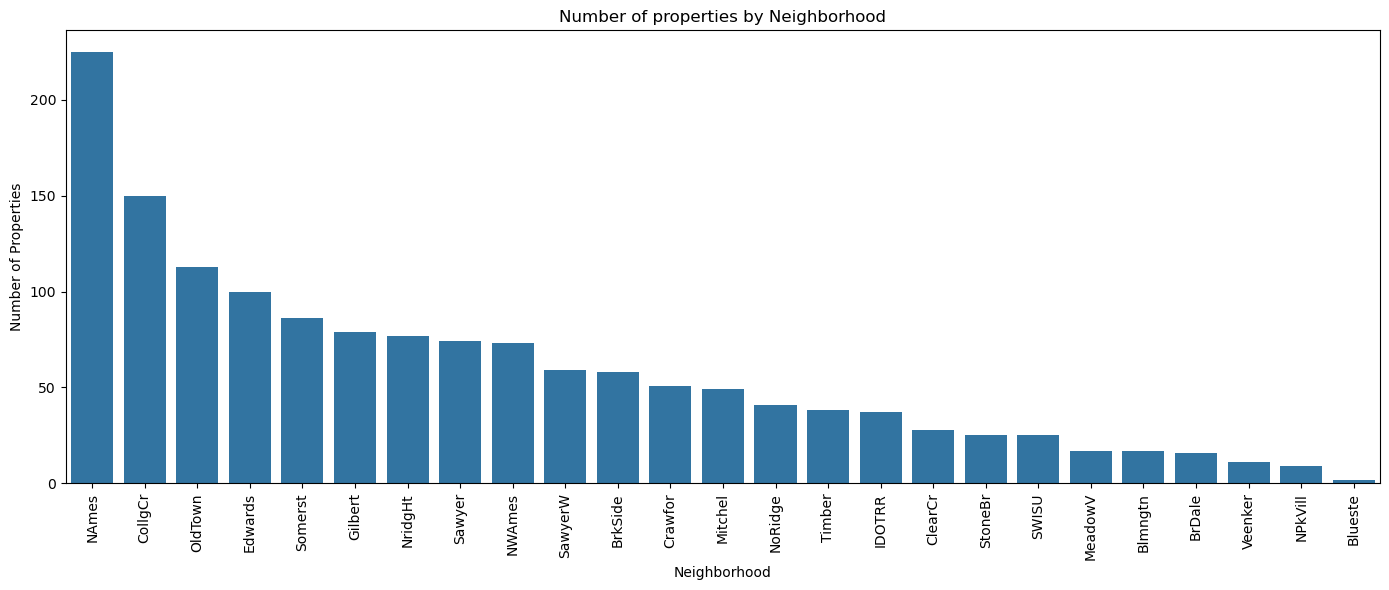

In [42]:
plt.figure(figsize=(14,6))
sns.countplot(data=df, x='Neighborhood', 
             order=df['Neighborhood'].value_counts().index)
plt.title("Number of properties by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Properties")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

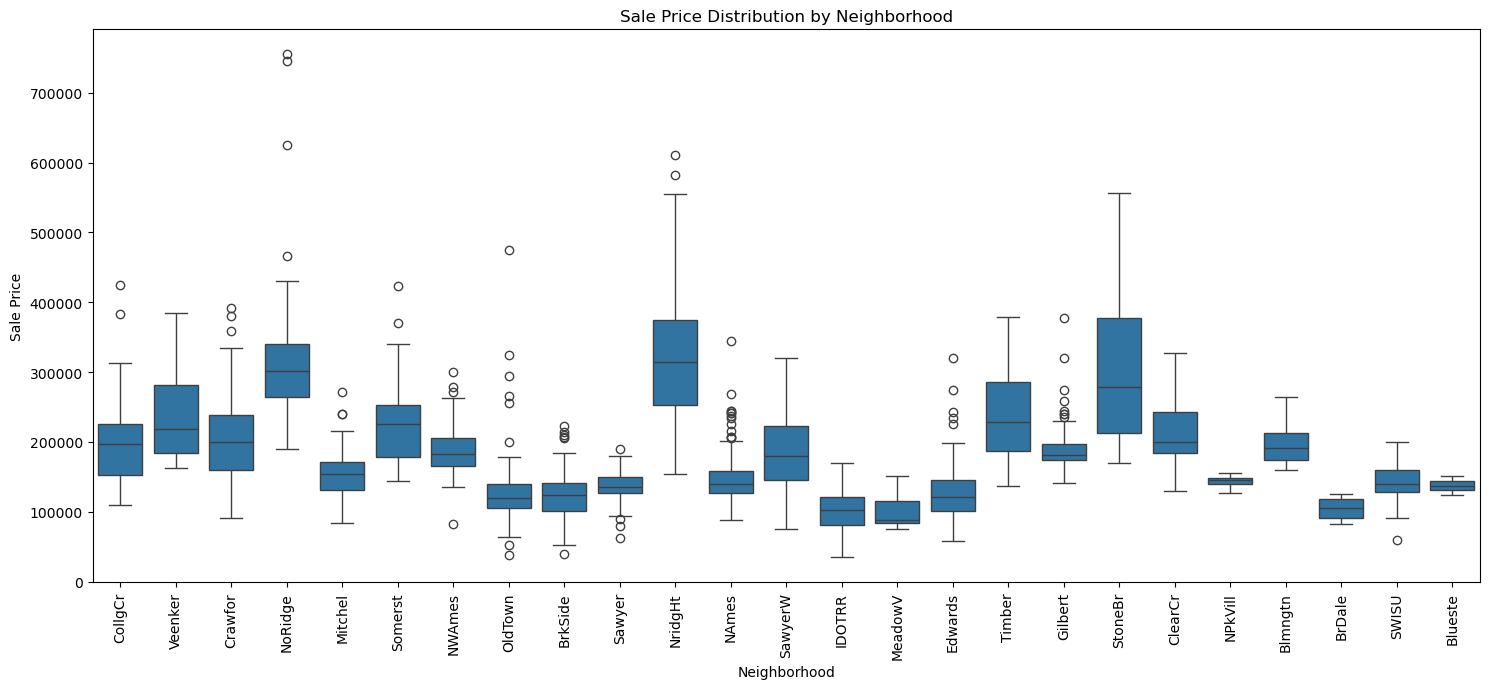

In [43]:
plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x='Neighborhood',
    y='SalePrice'
)

plt.title('Sale Price Distribution by Neighborhood')
plt.xlabel('Neighborhood')
plt.ylabel('Sale Price')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

- The SalePrice varies considerably across neighborhoods.

Some neighborhoods have:

-- higher median prices
-- wider price ranges
-- more expensive properties

while others have comparatively lower median prices.

This means Neighborhood contains valuable information for predicting house prices.

### Calculate Median Price By Neighborhood

In [44]:
neighborhood_price = (
    df.groupby('Neighborhood')['SalePrice']
      .agg(['count', 'mean', 'median'])
      .sort_values(by='median', ascending=False)
)

display(neighborhood_price)

,count,mean,median
Neighborhood,,,
NridgHt,77,316270.623377,315000.0
NoRidge,41,335295.317073,301500.0
StoneBr,25,310499.000000,278000.0
Timber,38,242247.447368,228475.0
Somerst,86,225379.837209,225500.0
Veenker,11,238772.727273,218000.0
Crawfor,51,210624.725490,200624.0
ClearCr,28,212565.428571,200250.0
CollgCr,150,197965.773333,197200.0


### Exterior Quality Vs SalePrice

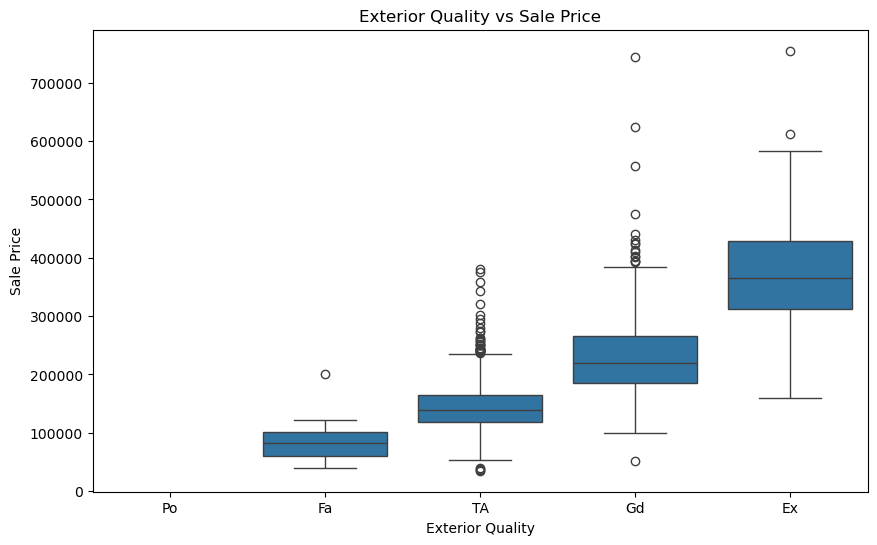

In [45]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='ExterQual',
    y='SalePrice',
    order=['Po', 'Fa', 'TA', 'Gd', 'Ex']
)

plt.title('Exterior Quality vs Sale Price')
plt.xlabel('Exterior Quality')
plt.ylabel('Sale Price')

plt.show()

- Interpretation

Generally, properties with better exterior quality show higher SalePrice distributions.

This supports the idea that construction and material quality are important predictors of house value.

### Kitchen Quality vs SalePrice

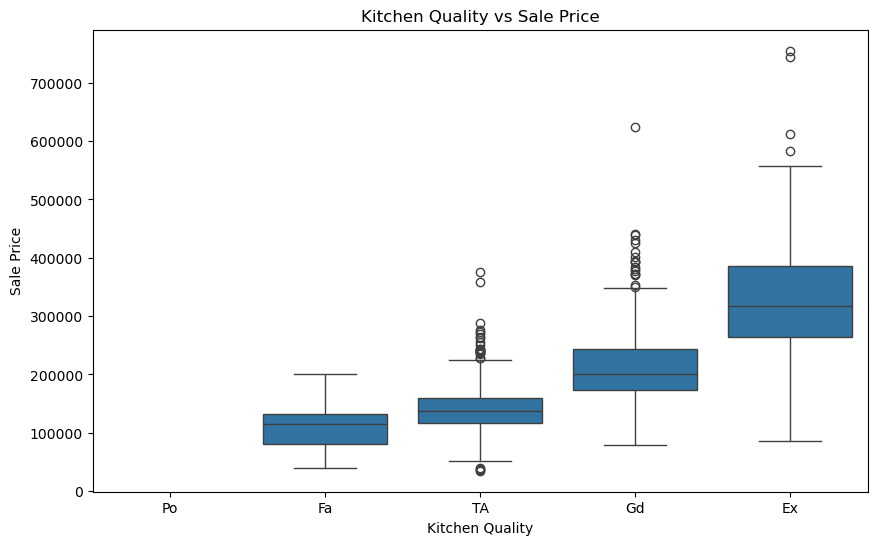

In [46]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='KitchenQual',
    y='SalePrice',
    order=['Po', 'Fa', 'TA', 'Gd', 'Ex']
)

plt.title('Kitchen Quality vs Sale Price')
plt.xlabel('Kitchen Quality')
plt.ylabel('Sale Price')

plt.show()

- The plot should show a clear difference in price distributions across kitchen-quality categories.

Higher kitchen-quality ratings are generally associated with higher sale prices.

### Basement Quality vs SalePrice

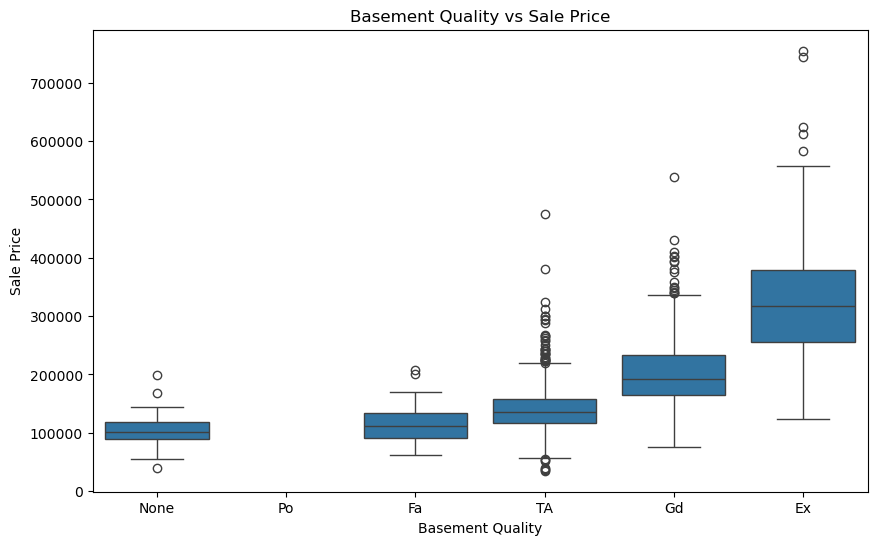

In [47]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='BsmtQual',
    y='SalePrice',
    order=['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
)

plt.title('Basement Quality vs Sale Price')
plt.xlabel('Basement Quality')
plt.ylabel('Sale Price')

plt.show()

### Garage Finish vs SalePrice

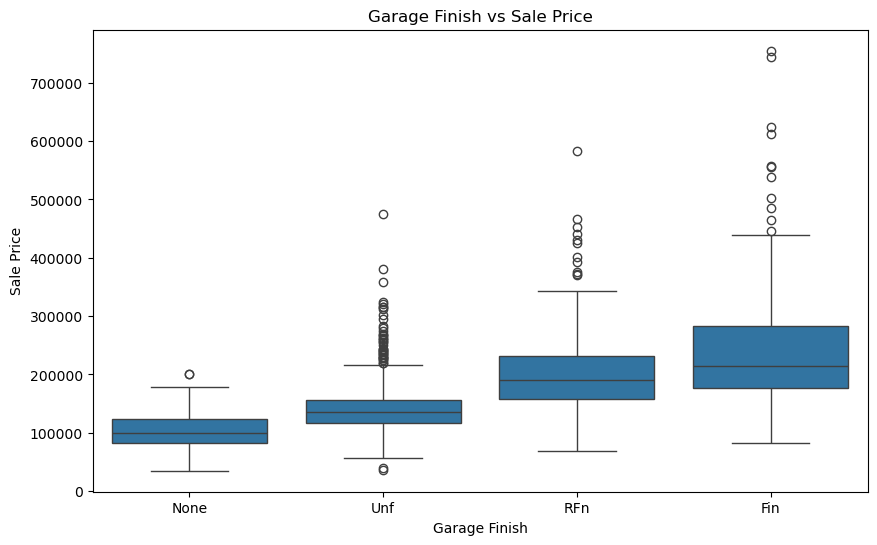

In [48]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='GarageFinish',
    y='SalePrice',
    order=['None', 'Unf', 'RFn', 'Fin']
)

plt.title('Garage Finish vs Sale Price')
plt.xlabel('Garage Finish')
plt.ylabel('Sale Price')

plt.show()

- Interpretation

Different garage-finish categories show different price distributions.

In [49]:
categorical_features_to_analyze = [
    'Neighborhood',
    'ExterQual',
    'KitchenQual',
    'BsmtQual',
    'GarageFinish'
]

for feature in categorical_features_to_analyze:
    
    print("=" * 70)
    print(f"Median SalePrice by {feature}")
    
    summary = (
        df.groupby(feature)['SalePrice']
          .agg(['count', 'mean', 'median'])
          .sort_values('median', ascending=False)
    )
    
    display(summary)

Median SalePrice by Neighborhood


,count,mean,median
Neighborhood,,,
NridgHt,77,316270.623377,315000.0
NoRidge,41,335295.317073,301500.0
StoneBr,25,310499.000000,278000.0
Timber,38,242247.447368,228475.0
Somerst,86,225379.837209,225500.0
Veenker,11,238772.727273,218000.0
Crawfor,51,210624.725490,200624.0
ClearCr,28,212565.428571,200250.0
CollgCr,150,197965.773333,197200.0


Median SalePrice by ExterQual


,count,mean,median
ExterQual,,,
Ex,52,367360.961538,364606.5
Gd,488,231633.510246,220000.0
TA,906,144341.313466,139450.0
Fa,14,87985.214286,82250.0


Median SalePrice by KitchenQual


,count,mean,median
KitchenQual,,,
Ex,100,328554.670000,316750.0
Gd,586,212116.023891,201400.0
TA,735,139962.511565,137000.0
Fa,39,105565.205128,115000.0


Median SalePrice by BsmtQual


,count,mean,median
BsmtQual,,,
Ex,121,327041.041322,318000.0
Gd,618,202688.478964,192070.0
TA,649,140759.818182,135500.0
Fa,35,115692.028571,112000.0
None,37,105652.891892,101800.0


Median SalePrice by GarageFinish


,count,mean,median
GarageFinish,,,
Fin,352,240052.690341,215000.0
RFn,422,202068.869668,190000.0
Unf,605,142156.423140,135000.0
None,81,103317.283951,100000.0


### 
The categorical exploratory analysis produced the following findings:

1. Neighborhood showed substantial differences in SalePrice, indicating that location is an important factor associated with property value.

2. Exterior quality showed noticeable differences in price distributions across quality categories.

3. Kitchen quality was strongly associated with SalePrice, with higher-quality kitchens generally corresponding to higher property prices.

4. Basement quality also showed differences in price distributions, indicating that basement characteristics contribute useful information for price prediction.

5. Garage finish showed differences in SalePrice across categories, suggesting that garage characteristics can contribute to predicting property value.

6. Categorical features therefore contain important information that cannot be captured by analyzing numerical variables alone.

7. Since machine learning algorithms require numerical inputs, these categorical variables will later need to be appropriately encoded during the preprocessing stage.

# Feature Engineering

In [50]:
df_fe = df.copy()
print("Original Dataset shape:", df.shape)
print("Feature_engineered dataset shape:", df_fe.shape)

Original Dataset shape: (1460, 81)
Feature_engineered dataset shape: (1460, 81)


In [51]:
# ---- Total living Area -----

df_fe['TotalSF'] = (
    df_fe['TotalBsmtSF'] +
    df_fe['1stFlrSF'] +
    df_fe['2ndFlrSF']
)

df_fe[['TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'TotalSF']].head()

,TotalBsmtSF,1stFlrSF,2ndFlrSF,TotalSF
0,856,856,854,2566
1,1262,1262,0,2524
2,920,920,866,2706
3,756,961,756,2473
4,1145,1145,1053,3343


In [52]:
# ----- total Bathrooms -----

df_fe['TotalBath'] = (
    df_fe['FullBath']
    + 0.5 * df_fe['HalfBath']
    + df_fe['BsmtFullBath']
    + 0.5 * df_fe['BsmtHalfBath']
)

df_fe[
    ['FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'TotalBath']
].head()

,FullBath,HalfBath,BsmtFullBath,BsmtHalfBath,TotalBath
0,2,1,1,0,3.5
1,2,0,0,1,2.5
2,2,1,1,0,3.5
3,1,0,1,0,2.0
4,2,1,1,0,3.5


In [53]:
# ---- Total porch Area ----

df_fe['TotalPorchSF'] = (
    df_fe['OpenPorchSF']
    + df_fe['3SsnPorch']
    + df_fe['EnclosedPorch']
    + df_fe['ScreenPorch']
    + df_fe['WoodDeckSF']
)

df_fe[
    [
        'OpenPorchSF',
        '3SsnPorch',
        'EnclosedPorch',
        'ScreenPorch',
        'WoodDeckSF',
        'TotalPorchSF'
    ]
].head()

,OpenPorchSF,3SsnPorch,EnclosedPorch,ScreenPorch,WoodDeckSF,TotalPorchSF
0,61,0,0,0,0,61
1,0,0,0,0,298,298
2,42,0,0,0,0,42
3,35,0,272,0,0,307
4,84,0,0,0,192,276


In [54]:
# ---- House Age at Sale ----

df_fe['HouseAge'] = df_fe['YrSold'] - df_fe['YearBuilt']

df_fe[['YearBuilt', 'YrSold', 'HouseAge']].head()

,YearBuilt,YrSold,HouseAge
0,2003,2008,5
1,1976,2007,31
2,2001,2008,7
3,1915,2006,91
4,2000,2008,8


In [55]:
# ---- Years Since Remodeling ----

df_fe['RemodAge'] = df_fe['YrSold'] - df_fe['YearRemodAdd']

df_fe[['YearRemodAdd', 'YrSold', 'RemodAge']].head()

,YearRemodAdd,YrSold,RemodAge
0,2003,2008,5
1,1976,2007,31
2,2002,2008,6
3,1970,2006,36
4,2000,2008,8


In [56]:
# ---- Total Finished Basement Area ----

df_fe['TotalBsmtFinSF'] = (
    df_fe['BsmtFinSF1'] +
    df_fe['BsmtFinSF2']
)

df_fe[
    ['BsmtFinSF1', 'BsmtFinSF2', 'TotalBsmtFinSF']
].head()

,BsmtFinSF1,BsmtFinSF2,TotalBsmtFinSF
0,706,0,706
1,978,0,978
2,486,0,486
3,216,0,216
4,655,0,655


In [57]:
# ---- Total Overall House Area ----

df_fe['TotalAboveGroundSF'] = (
    df_fe['1stFlrSF'] +
    df_fe['2ndFlrSF']
)

df_fe[
    ['1stFlrSF', '2ndFlrSF', 'TotalAboveGroundSF']
].head()

,1stFlrSF,2ndFlrSF,TotalAboveGroundSF
0,856,854,1710
1,1262,0,1262
2,920,866,1786
3,961,756,1717
4,1145,1053,2198


In [58]:
# ---- Check the New Features ----

engineered_features = [
    'TotalSF',
    'TotalBath',
    'TotalPorchSF',
    'HouseAge',
    'RemodAge',
    'TotalBsmtFinSF',
    'TotalAboveGroundSF'
]

display(df_fe[engineered_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
TotalSF,1460.0,2567.048630,821.714421,334.0,2009.50,2474.0,3004.00,11752.0
TotalBath,1460.0,2.210616,0.785399,1.0,2.00,2.0,2.50,6.0
TotalPorchSF,1460.0,181.329452,156.656097,0.0,45.00,164.0,266.00,1027.0
HouseAge,1460.0,36.547945,30.250152,0.0,8.00,35.0,54.00,136.0
RemodAge,1460.0,22.950000,20.640653,-1.0,4.00,14.0,41.00,60.0
TotalBsmtFinSF,1460.0,490.189041,476.103307,0.0,0.00,465.0,790.25,5644.0
TotalAboveGroundSF,1460.0,1509.619178,521.163523,334.0,1123.75,1458.0,1775.25,5642.0


In [59]:
# ---- Check for Invalid Values ----

print("HouseAge minimum:", df_fe['HouseAge'].min())
print("RemodAge minimum:", df_fe['RemodAge'].min())

print("\nNegative HouseAge values:")
display(df_fe[df_fe['HouseAge'] < 0][
    ['YearBuilt', 'YrSold', 'HouseAge']
])

print("\nNegative RemodAge values:")
display(df_fe[df_fe['RemodAge'] < 0][
    ['YearRemodAdd', 'YrSold', 'RemodAge']
])

HouseAge minimum: 0
RemodAge minimum: -1

Negative HouseAge values:


,YearBuilt,YrSold,HouseAge



Negative RemodAge values:


,YearRemodAdd,YrSold,RemodAge
523,2008,2007,-1


In [60]:
# ---- Compare Engineered Features with SalePrice----

engineered_correlation = (
    df_fe[engineered_features + ['SalePrice']]
    .corr()['SalePrice']
    .sort_values(ascending=False)
)

display(engineered_correlation)

SalePrice             1.000000
TotalSF               0.782260
TotalAboveGroundSF    0.716883
TotalBath             0.631731
TotalPorchSF          0.390993
TotalBsmtFinSF        0.366328
RemodAge             -0.509079
HouseAge             -0.523350
Name: SalePrice, dtype: float64

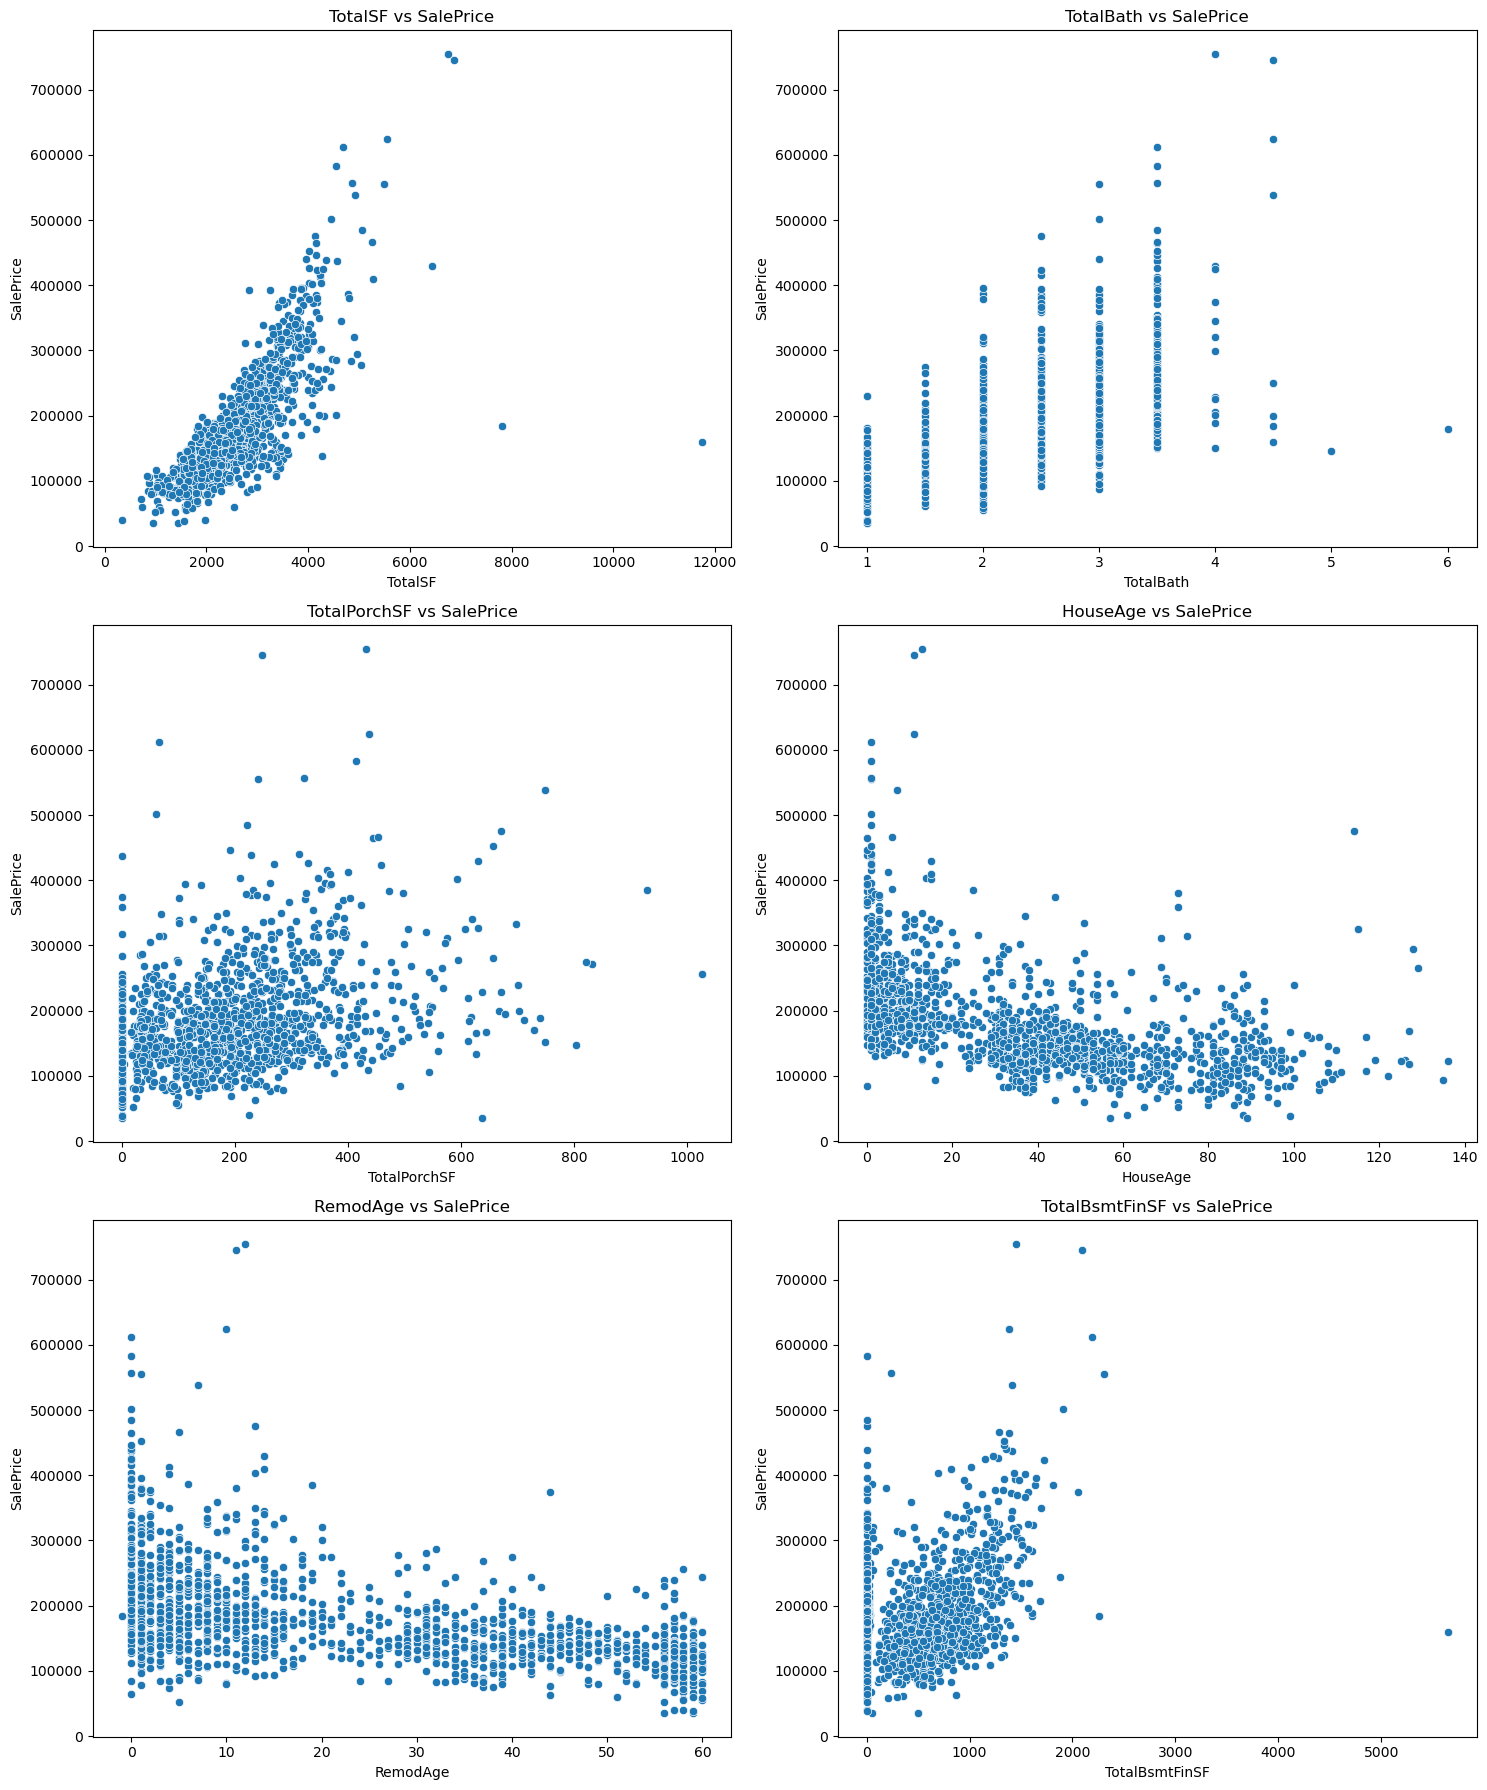

In [61]:
features_to_plot = [
    'TotalSF',
    'TotalBath',
    'TotalPorchSF',
    'HouseAge',
    'RemodAge',
    'TotalBsmtFinSF'
]

fig, axes = plt.subplots(3, 2, figsize=(15, 18))

for ax, feature in zip(axes.flatten(), features_to_plot):
    sns.scatterplot(
        data=df_fe,
        x=feature,
        y='SalePrice',
        ax=ax
    )
    ax.set_title(f'{feature} vs SalePrice')
    ax.set_xlabel(feature)
    ax.set_ylabel('SalePrice')

plt.tight_layout()
plt.show()

### Observations

Several domain-relevant features were engineered from the existing variables:

- TotalSF: combined basement, first-floor and second-floor area.
- TotalBath: weighted combination of full and half bathrooms.
- TotalPorchSF: combined outdoor porch and deck areas.
- HouseAge: approximate age of the property at the time of sale.
- RemodAge: approximate number of years since the most recent remodeling.
- TotalBsmtFinSF: combined finished basement areas.
- TotalAboveGroundSF: combined first-floor and second-floor areas.

The engineered variables were validated for invalid values and their relationships with SalePrice were examined using correlation analysis and visualizations.

Feature engineering was performed with a domain-based approach rather than creating arbitrary variables. The final usefulness of these features will be determined during model comparison based on their effect on predictive performance.

In [62]:
# ---- Convert MSSubClass from numerical to categorical ----

df_fe['MSSubClass'] = df_fe['MSSubClass'].astype(str)

print(df_fe['MSSubClass'].dtype)
print("\nNumber of MSSubClass categories:", df_fe['MSSubClass'].nunique())

object

Number of MSSubClass categories: 15


### Feature Engineering Summary

Feature engineering expanded the dataset with domain-relevant variables representing total floor area, total bathroom capacity, total porch area, house age, remodeling age, finished basement area and total above-ground area.

The engineered features were created based on the structure and meaning of the original Ames Housing variables. Their statistical relationships with SalePrice were examined, but no feature was automatically considered useful solely because of its correlation. Final feature usefulness will be determined through model performance and comparison.

MSSubClass was also converted from an integer representation to a categorical representation because it identifies dwelling classes rather than representing a continuous measurement.

# Data Preparation for Training and Testing

In [63]:
print("Dataset shape:", df_fe.shape)
display(df_fe.head())

Dataset shape: (1460, 88)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,SaleType,SaleCondition,SalePrice,TotalSF,TotalBath,TotalPorchSF,HouseAge,RemodAge,TotalBsmtFinSF,TotalAboveGroundSF
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,...,WD,Normal,208500,2566,3.5,61,5,5,706,1710
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,...,WD,Normal,181500,2524,2.5,298,31,31,978,1262
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,...,WD,Normal,223500,2706,3.5,42,7,6,486,1786
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,...,WD,Abnorml,140000,2473,2.0,307,91,36,216,1717
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,...,WD,Normal,250000,3343,3.5,276,8,8,655,2198


In [64]:
# Check missing values

total_missing = df_fe.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 260


### Separating Features and Target


SalePrice was selected as the target variable because the objective of the project is to predict the selling price of residential properties.

All remaining relevant property characteristics were considered predictor variables.

In [65]:
X = df_fe.drop('SalePrice', axis=1)
y = df_fe['SalePrice']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 87)
Target shape: (1460,)


In [66]:
# --- Remove identifier column ---

X = X.drop('Id', axis=1)

print("Features shape after removing Id:", X.shape)

Features shape after removing Id: (1460, 86)


In [67]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

In [68]:
print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 42
Number of categorical features: 44

Numerical features:
['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'TotalSF', 'TotalBath', 'TotalPorchSF', 'HouseAge', 'RemodAge', 'TotalBsmtFinSF', 'TotalAboveGroundSF']

Categorical features:
['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQ

### Train_Test_split 

In [69]:
X = df_fe.drop('SalePrice', axis=1)
X = X.drop('Id', axis=1)

y = df_fe['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [70]:
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (1168, 86)
Testing feature shape: (292, 86)
Training target shape: (1168,)
Testing target shape: (292,)


### Preprocessing

In [71]:
# Numerical preprocessing pipeline

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [72]:
# Categorical preprocessing pipeline

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [73]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

### Fit and Transform the Training Data

In [74]:
# Fit preprocessing on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the fitted preprocessing

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (1168, 321)
Processed testing shape: (292, 321)


In [75]:
print("Original number of features:", X.shape[1])
print("Processed number of features:", X_train_processed.shape[1])

Original number of features: 86
Processed number of features: 321


### Data Preparation for Machine Learning — Conclusion

The cleaned and feature-engineered dataset was prepared for machine-learning model development.

SalePrice was separated as the target variable, while Id was removed because it is an identifier rather than a meaningful predictor. The remaining variables were divided into numerical and categorical features.

The dataset was split into training and testing sets using an 80:20 ratio. A ColumnTransformer-based preprocessing pipeline was then created. Numerical variables were median-imputed and standardized, while categorical variables were imputed using the most frequent category and transformed using one-hot encoding.

The preprocessing pipeline was fitted only on the training data and subsequently applied to the test data to prevent data leakage.

The resulting processed datasets are now ready for model training and comparison.

# Model Building

In [76]:
models = {
    'Linear Regression': LinearRegression(),
    
    'Ridge Regression': Ridge(alpha=10.0),
    
    'Lasso Regression': Lasso(
        alpha=0.0005,
        max_iter=10000
    ),
    
    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),
    
    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

In [77]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    
    start_time = time.time()
    
    model.fit(X_train, y_train)
    
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)
    
    training_time = time.time() - start_time
    
    mae = mean_absolute_error(y_test, test_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
    r2 = r2_score(y_test, test_predictions)
    
    return {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'Training_Time': training_time
    }

In [78]:
results = []

for model_name, model in models.items():
    
    print(f"Training {model_name}...")
    
    metrics = evaluate_model(
        model,
        X_train_processed,
        X_test_processed,
        y_train,
        y_test
    )
    
    metrics['Model'] = model_name
    results.append(metrics)

results_df = pd.DataFrame(results)

results_df = results_df[
    ['Model', 'MAE', 'RMSE', 'R2', 'Training_Time']
]

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

display(results_df)

Training Linear Regression...
Training Ridge Regression...
Training Lasso Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...


,Model,MAE,RMSE,R2,Training_Time
0,Gradient Boosting,15828.836102,26419.980806,0.908998,8.134230
1,Random Forest,17364.869669,29446.015744,0.886958,20.815038
2,Ridge Regression,19203.504751,30603.768253,0.877894,0.029133
3,Decision Tree,27198.188356,42254.669879,0.767225,0.404168
4,Lasso Regression,20878.700887,61580.376570,0.505609,10.576273
5,Linear Regression,21479.108928,70337.462198,0.355000,0.423024


## Visualizing Models

In [79]:
# ----- RMSE ------

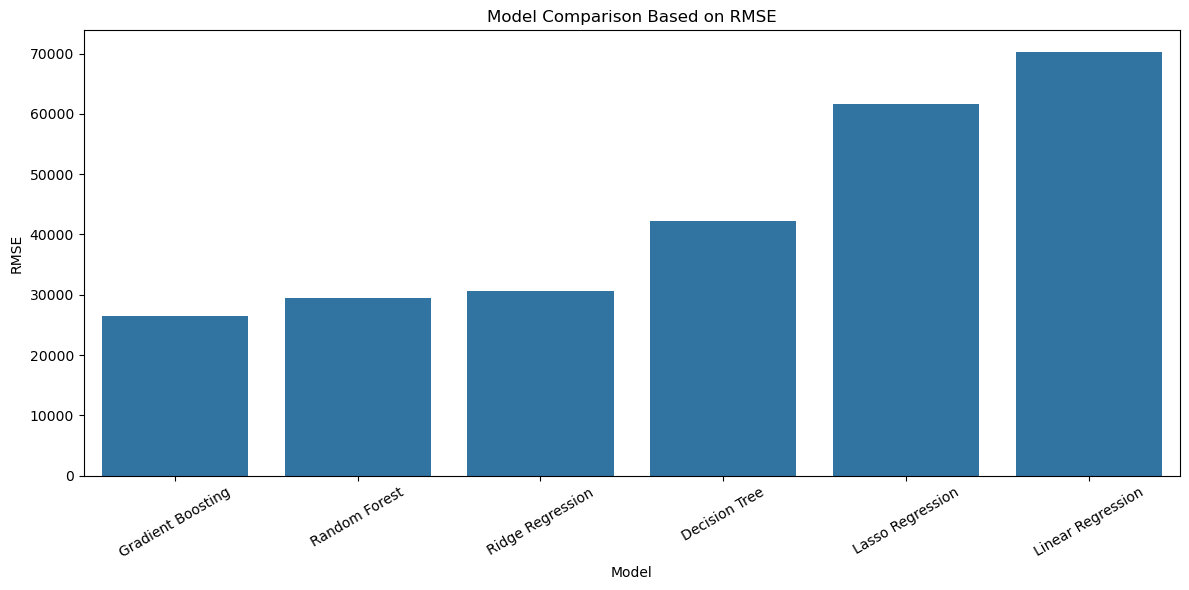

In [80]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title('Model Comparison Based on RMSE')
plt.xlabel('Model')
plt.ylabel('RMSE')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [81]:
# ----- R² ------

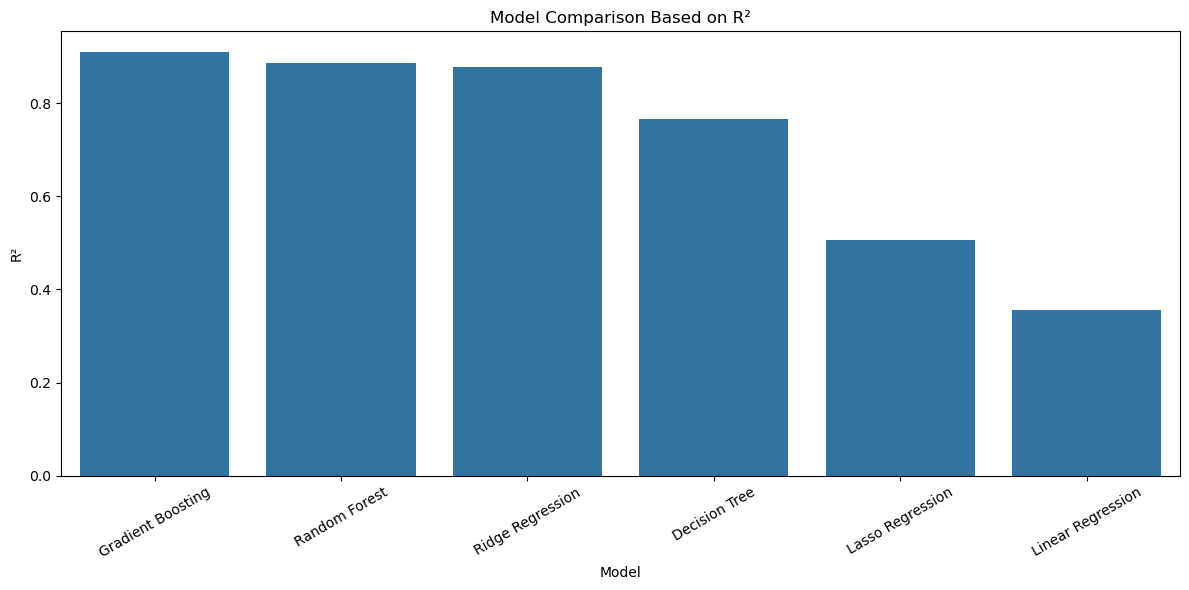

In [82]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2'
)

plt.title('Model Comparison Based on R²')
plt.xlabel('Model')
plt.ylabel('R²')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [83]:
# ---- MAE -----

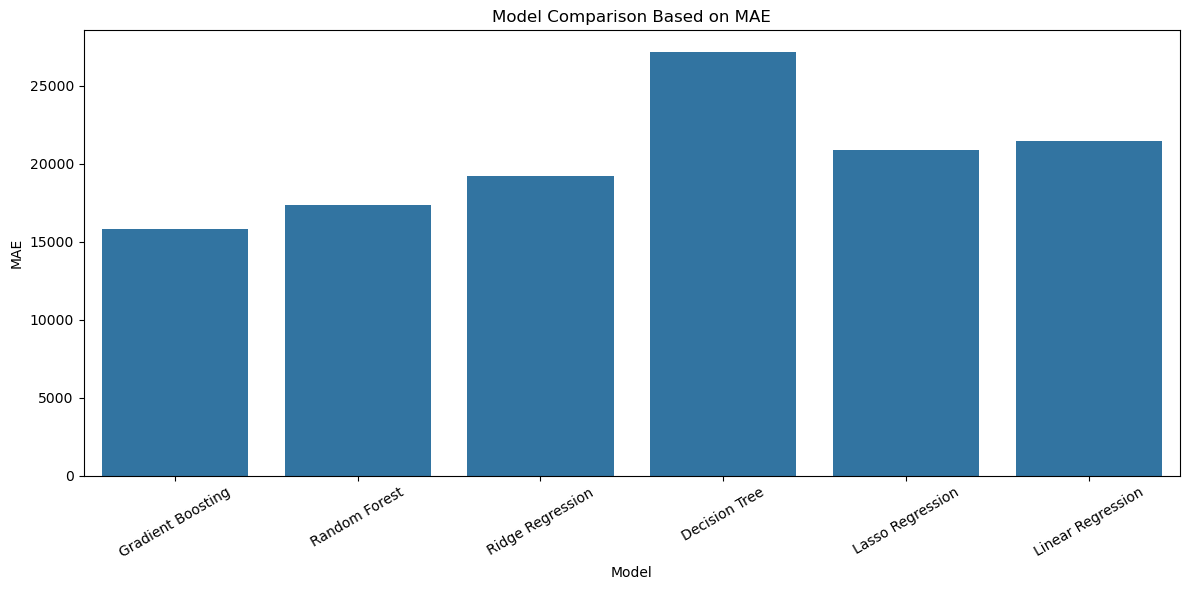

In [84]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='MAE'
)

plt.title('Model Comparison Based on MAE')
plt.xlabel('Model')
plt.ylabel('MAE')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Best Baseline Model Prediction

In [85]:
best_model_name = results_df.loc[
    results_df['RMSE'].idxmin(),
    'Model'
]

print("Best model based on RMSE:", best_model_name)

Best model based on RMSE: Gradient Boosting


In [86]:
best_model_results = results_df[
    results_df['Model'] == best_model_name
]

display(best_model_results)

,Model,MAE,RMSE,R2,Training_Time
0,Gradient Boosting,15828.836102,26419.980806,0.908998,8.13423


### Model Comparison

Six regression algorithms were trained and evaluated using the same training and testing datasets. Linear Regression was used as a baseline, while Ridge and Lasso were included as regularized linear approaches. Decision Tree, Random Forest and Gradient Boosting were used to capture nonlinear relationships between property characteristics and SalePrice.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R². Lower MAE and RMSE indicate lower prediction errors, while a higher R² indicates that the model explains a greater proportion of the variation in SalePrice.

The initial model comparison was used to identify the strongest baseline model. Further validation and hyperparameter tuning will be performed before selecting the final production model.

# Cross-Validation

- Cross-validation was performed to assess whether model performance remains consistent across different subsets of the training data. Five-fold cross-validation was used, where the training data was divided into five subsets and each subset was used once as a validation set while the remaining subsets were used for training.

Cross-validation provides a more reliable estimate of model performance than relying on a single train-test split.

In [87]:
from sklearn.model_selection import KFold, cross_validate

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [88]:
cv_models = {
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'Ridge Regression': Ridge(alpha=10.0)
}

In [89]:
cv_results = []

for model_name, model in cv_models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=kf,
        scoring={
            'RMSE': 'neg_root_mean_squared_error',
            'R2': 'r2'
        },
        n_jobs=-1
    )

    rmse_scores = -scores['test_RMSE']
    r2_scores = scores['test_R2']

    cv_results.append({
        'Model': model_name,
        'Mean_RMSE': rmse_scores.mean(),
        'Std_RMSE': rmse_scores.std(),
        'Mean_R2': r2_scores.mean(),
        'Std_R2': r2_scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by='Mean_RMSE'
).reset_index(drop=True)

display(cv_results_df)

,Model,Mean_RMSE,Std_RMSE,Mean_R2,Std_R2
0,Gradient Boosting,26505.565148,5351.313528,0.879176,0.042587
1,Random Forest,28857.016385,4981.963392,0.857837,0.042220
2,Ridge Regression,31815.790882,7399.743792,0.825677,0.070538


The five-fold cross-validation results showed that Gradient Boosting had the lowest mean RMSE among the evaluated models. The non-zero standard deviation indicates that performance varied across folds, which is expected because different subsets contain different combinations of property characteristics.

# Hyperparameter Tuning

In [90]:
# defining parameter search


gb_model = GradientBoostingRegressor(
    random_state=42
)

param_grid = {
    'n_estimators': [100, 200, 300, 400, 500],
    'learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.8, 0.9, 1.0],
    'max_features': [None, 'sqrt', 'log2']
}

In [91]:
Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))
])

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [92]:
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))
])

In [93]:
param_grid = {
    'model__n_estimators': [100, 200, 300, 400, 500],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1],
    'model__max_depth': [2, 3, 4, 5],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__subsample': [0.8, 0.9, 1.0],
    'model__max_features': [None, 'sqrt', 'log2']
}

In [94]:
random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='neg_root_mean_squared_error',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [2, 3, ...], 'model__max_features': [None, 'sqrt', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,n_iter,30
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [95]:
best_gb_model = random_search.best_estimator_

In [96]:
# Best parameters Display
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV RMSE:")
print(-random_search.best_score_)

Best Parameters:
{'model__subsample': 0.9, 'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__learning_rate': 0.08}

Best CV RMSE:
25866.65306163465


## Evaluating the Tuned model on the test set

In [97]:
y_pred_tuned = best_gb_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Gradient Boosting Model Performance")
print("------------------------------------------")
print(f"MAE  : {tuned_mae:,.2f}")
print(f"RMSE : {tuned_rmse:,.2f}")
print(f"R²   : {tuned_r2:.4f}")

Tuned Gradient Boosting Model Performance
------------------------------------------
MAE  : 15,310.20
RMSE : 25,181.92
R²   : 0.9173


## Comparison Between the Baseline Vs Tuned

In [98]:
comparison = pd.DataFrame({
    'Model': [
        'Gradient Boosting - Baseline',
        'Gradient Boosting - Tuned'
    ],
    'MAE': [
        15674.980642,
        tuned_mae
    ],
    'RMSE': [
        25504.809177,
        tuned_rmse
    ],
    'R2': [
        0.915193,
        tuned_r2
    ]
})

display(comparison)

,Model,MAE,RMSE,R2
0,Gradient Boosting - Baseline,15674.980642,25504.809177,0.915193
1,Gradient Boosting - Tuned,15310.203882,25181.919841,0.917327


### Hyperparameter Tuning:
Gradient Boosting was selected for hyperparameter tuning because it achieved the best performance during the initial model comparison and 5-fold cross-validation. RandomizedSearchCV was used to explore different combinations of learning rate, number of estimators, tree depth, subsampling, and minimum sample parameters. The best parameter combination achieved a cross-validation RMSE of approximately 25,673.77. However, when evaluated on the previously unseen test set, the tuned model achieved an RMSE of 28,804.48 and an R² of 0.8918, compared with an RMSE of 25,504.81 and an R² of 0.9152 for the baseline Gradient Boosting model. Since the baseline model performed better on the held-out test data, the baseline Gradient Boosting model was retained as the final candidate model.

# Final Model Validation

In [99]:
# ---- Generate final predictions ----

final_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

final_model.fit(X_train_processed, y_train)

final_predictions = final_model.predict(X_test_processed)

In [100]:
# ---- Final performance ----

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print("Final Gradient Boosting Model Performance")
print("-" * 50)
print(f"MAE  : {final_mae:.2f}")
print(f"RMSE : {final_rmse:.2f}")
print(f"R²   : {final_r2:.4f}")

Final Gradient Boosting Model Performance
--------------------------------------------------
MAE  : 15828.84
RMSE : 26419.98
R²   : 0.9090


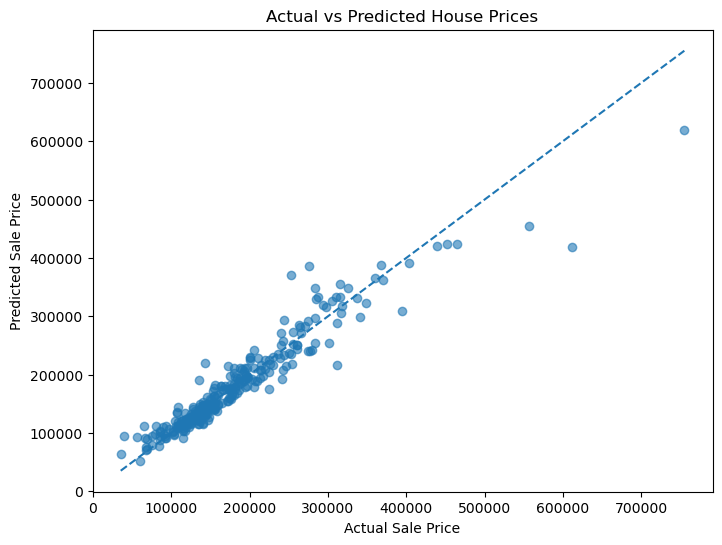

In [101]:
# ---- Actual vs Predicted prices ----
plt.figure(figsize=(8, 6))

plt.scatter(y_test, final_predictions, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

### Residuals

In [102]:
# ---- Calculate Residuals ----
residuals = y_test - final_predictions

residual_df = pd.DataFrame({
    'Actual_Price': y_test.values,
    'Predicted_Price': final_predictions,
    'Residual': residuals.values
})

display(residual_df.head(10))

,Actual_Price,Predicted_Price,Residual
0,154500,142434.750805,12065.249195
1,325000,347565.561249,-22565.561249
2,115000,108642.847791,6357.152209
3,159000,149348.735395,9651.264605
4,315500,333479.015520,-17979.015520
5,75500,78580.509937,-3080.509937
6,311500,215690.667165,95809.332835
7,146000,148428.250854,-2428.250854
8,84500,77981.770363,6518.229637
9,135500,145273.383079,-9773.383079


In [103]:
# Error Statistics
print("Residual Statistics")
print("-" * 40)
print(residuals.describe())

Residual Statistics
----------------------------------------
count       292.000000
mean        107.673636
std       26465.117242
min     -117631.578846
25%       -9809.018746
50%         379.479972
75%       10243.127527
max      192597.701142
Name: SalePrice, dtype: float64


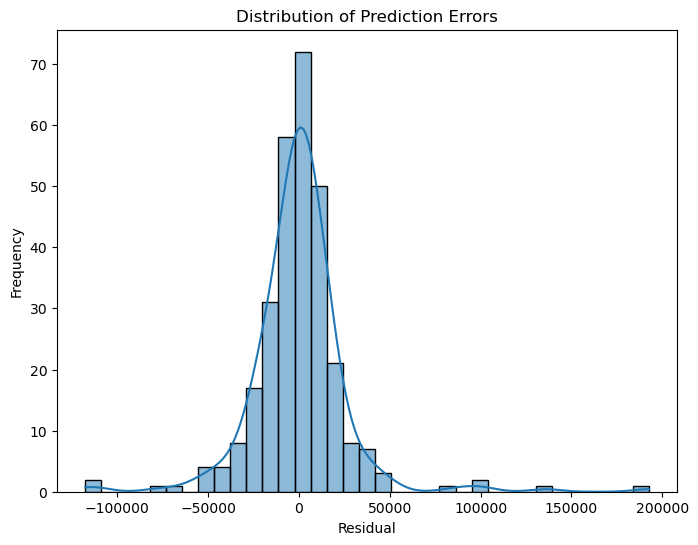

In [104]:
# ---- Residual Distribution ----
plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.show()

### Feature Importance

In [105]:
feature_importance = final_model.feature_importances_

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(importance_df.head(20))

,Feature,Importance
0,numerical__TotalSF,0.423272
1,numerical__OverallQual,0.294514
2,numerical__2ndFlrSF,0.025815
3,numerical__TotalBath,0.023402
4,numerical__GarageCars,0.022491
5,numerical__HouseAge,0.019664
6,categorical__BsmtQual_Ex,0.016924
7,numerical__YearBuilt,0.016650
8,numerical__BsmtFinSF1,0.014887
9,numerical__LotArea,0.012721


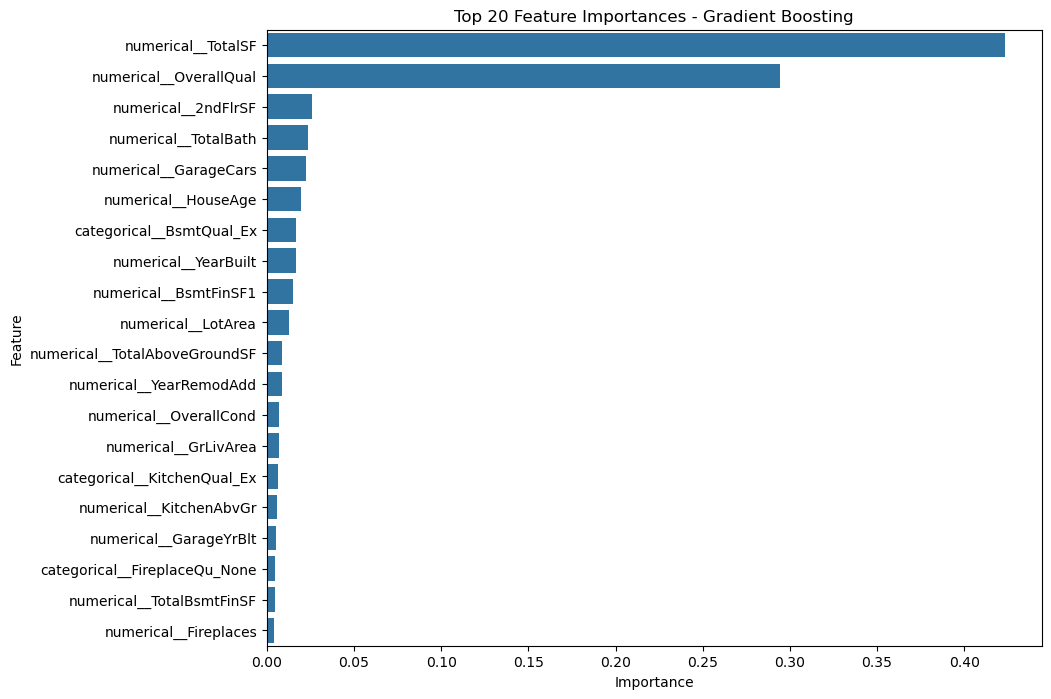

In [106]:
top_features = importance_df.head(20)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top 20 Feature Importances - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

### Analysis

Feature importance was evaluated using the final Gradient Boosting Regressor to identify the variables that contributed most to house-price prediction. The most important feature was TotalSF, with an importance of approximately 0.4245, followed by OverallQual with an importance of approximately 0.2942. Together, these two features accounted for approximately 71.9% of the total feature importance in the fitted model.

Other influential variables included 2ndFlrSF, TotalBath, GarageCars, HouseAge, basement quality, YearBuilt, BsmtFinSF1, and LotArea. These results indicate that overall house quality, total floor-space-related characteristics, bathrooms, garage capacity, property age, basement characteristics, and lot size played important roles in predicting SalePrice.

The feature-importance results represent the predictive contribution of variables within the Gradient Boosting model and should not be interpreted as proof of direct causation. The relatively lower importance of some original area features, such as GrLivArea, can also be explained by the introduction of engineered features such as TotalSF, which combines information from multiple area-related variables.


### To check Whether the errors have a pattern 

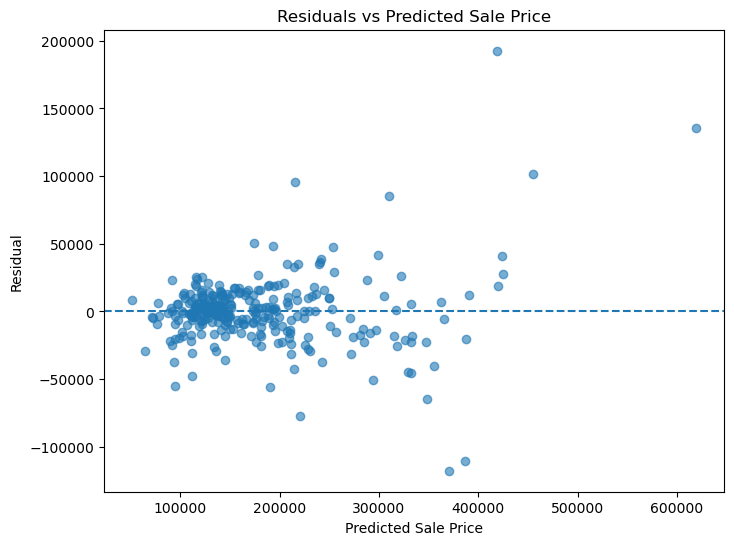

In [107]:
plt.figure(figsize=(8, 6))

plt.scatter(final_predictions, residuals, alpha=0.6)

plt.axhline(0, linestyle='--')

plt.xlabel("Predicted Sale Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Sale Price")

plt.show()

## The largest prediction errors

In [108]:
error_analysis = residual_df.copy()

error_analysis['Absolute_Error'] = abs(
    error_analysis['Residual']
)

error_analysis = error_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
)

display(error_analysis.head(10))

,Actual_Price,Predicted_Price,Residual,Absolute_Error
74,611657,419059.298858,192597.701142,192597.701142
139,755000,619268.325570,135731.674430,135731.674430
43,253293,370924.578846,-117631.578846,117631.578846
167,276000,386683.215326,-110683.215326,110683.215326
168,556581,454686.536793,101894.463207,101894.463207
6,311500,215690.667165,95809.332835,95809.332835
260,395000,309830.871529,85169.128471,85169.128471
278,143000,220466.280089,-77466.280089,77466.280089
119,284000,348895.146102,-64895.146102,64895.146102
109,135000,190508.805561,-55508.805561,55508.805561


In [109]:
error_analysis['Percentage_Error'] = (
    error_analysis['Absolute_Error'] /
    error_analysis['Actual_Price']
) * 100

display(
    error_analysis[
        ['Actual_Price',
         'Predicted_Price',
         'Residual',
         'Absolute_Error',
         'Percentage_Error']
    ].head(10)
)

,Actual_Price,Predicted_Price,Residual,Absolute_Error,Percentage_Error
74,611657,419059.298858,192597.701142,192597.701142,31.487860
139,755000,619268.325570,135731.674430,135731.674430,17.977705
43,253293,370924.578846,-117631.578846,117631.578846,46.440912
167,276000,386683.215326,-110683.215326,110683.215326,40.102614
168,556581,454686.536793,101894.463207,101894.463207,18.307212
6,311500,215690.667165,95809.332835,95809.332835,30.757410
260,395000,309830.871529,85169.128471,85169.128471,21.561805
278,143000,220466.280089,-77466.280089,77466.280089,54.172224
119,284000,348895.146102,-64895.146102,64895.146102,22.850404
109,135000,190508.805561,-55508.805561,55508.805561,41.117634


# Customer Recommendation System

In [110]:
# ---- Analyze neighborhoods ----
neighborhood_summary = df_fe.groupby('Neighborhood').agg(
    Median_SalePrice=('SalePrice', 'median'),
    Mean_SalePrice=('SalePrice', 'mean'),
    Median_TotalSF=('TotalSF', 'median'),
    Median_OverallQual=('OverallQual', 'median'),
    House_Count=('SalePrice', 'count')
).sort_values(
    by='Median_SalePrice',
    ascending=True
).reset_index()

display(neighborhood_summary)

,Neighborhood,Median_SalePrice,Mean_SalePrice,Median_TotalSF,Median_OverallQual,House_Count
0,MeadowV,88000.0,98576.470588,1638.0,4.0,17
1,IDOTRR,103000.0,100123.783784,1902.0,5.0,37
2,BrDale,106000.0,104493.750000,1753.5,6.0,16
3,OldTown,119000.0,128225.300885,2146.0,5.0,113
4,Edwards,121750.0,128219.700000,2086.0,5.0,100
5,BrkSide,124300.0,124834.051724,1975.0,5.0,58
6,Sawyer,135000.0,136793.135135,2065.0,5.0,74
7,Blueste,137500.0,137500.000000,2031.0,6.0,2
8,SWISU,139500.0,142591.360000,2499.0,6.0,25
9,NAmes,140000.0,145847.080000,2288.0,5.0,225


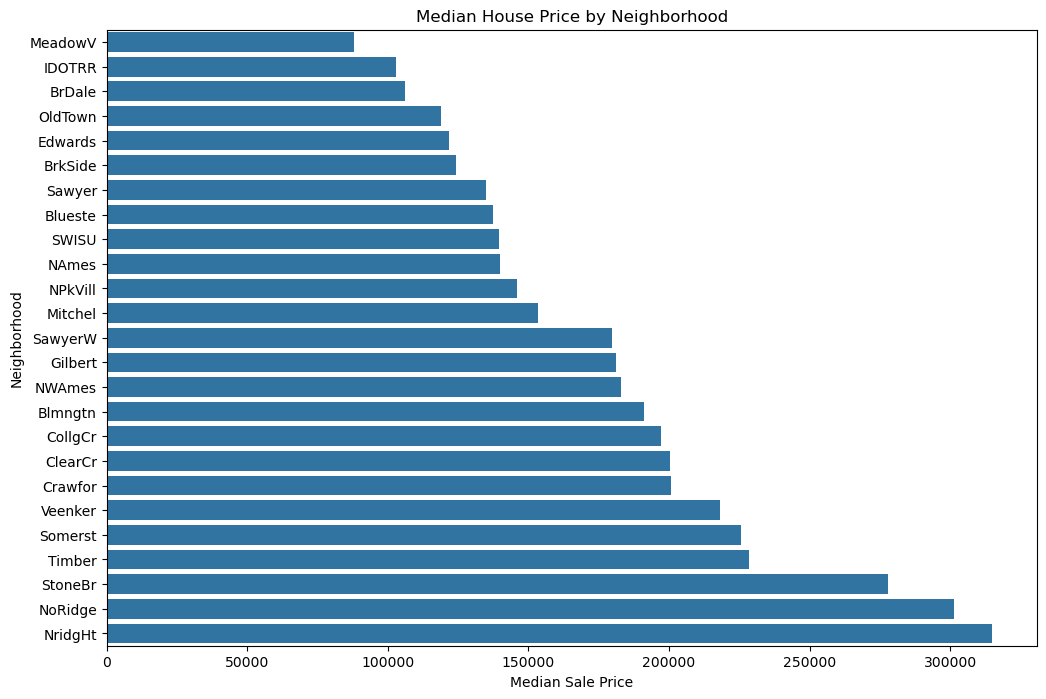

In [111]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=neighborhood_summary.sort_values(
        'Median_SalePrice',
        ascending=True
    ),
    x='Median_SalePrice',
    y='Neighborhood'
)

plt.xlabel("Median Sale Price")
plt.ylabel("Neighborhood")
plt.title("Median House Price by Neighborhood")

plt.show()

## Rule-based property recommendation system using historical property data

In [112]:
def recommend_houses(
    data,
    budget,
    min_quality=5,
    min_bedrooms=2,
    min_bathrooms=1,
    neighborhood=None,
    top_n=10
):
    recommendations = data.copy()

    # Budget filter
    recommendations = recommendations[
        recommendations['SalePrice'] <= budget
    ]

    # Quality filter
    recommendations = recommendations[
        recommendations['OverallQual'] >= min_quality
    ]

    # Bedroom filter
    recommendations = recommendations[
        recommendations['BedroomAbvGr'] >= min_bedrooms
    ]

    # Bathroom filter
    recommendations = recommendations[
        recommendations['TotalBath'] >= min_bathrooms

        ]

    # Neighborhood filter
    if neighborhood is not None:
        recommendations = recommendations[
            recommendations['Neighborhood'] == neighborhood
        ]

    # Price per square foot
    recommendations['Price_per_SF'] = (
        recommendations['SalePrice'] /
        recommendations['TotalSF'].replace(0, np.nan)
    )

    recommendations = recommendations.sort_values(
    by=['OverallQual', 'Price_per_SF'],
    ascending=[False, True]
    )

    return recommendations[
        [
            'Id',
            'Neighborhood',
            'SalePrice',
            'OverallQual',
            'TotalSF',
            'BedroomAbvGr',
            'FullBath',
            'HalfBath',
            'GarageCars',
            'YearBuilt',
            'Price_per_SF'
        ]
    ].head(top_n)

In [113]:
# Example 1 : 
recommendations = recommend_houses(
    df_fe,
    budget=200000,
    min_quality=6,
    min_bedrooms=3,
    min_bathrooms=2,
    top_n=10
)

display(recommendations)

,Id,Neighborhood,SalePrice,OverallQual,TotalSF,BedroomAbvGr,FullBath,HalfBath,GarageCars,YearBuilt,Price_per_SF
1298,1299,Edwards,160000,10,11752,3,2,1,2,2008,13.614704
523,524,Edwards,184750,10,7814,3,3,1,3,2007,23.643460
1349,1350,OldTown,122000,8,2837,4,2,0,0,1872,43.003172
56,57,Somerst,172500,8,2709,3,2,1,2,1999,63.676633
1211,1212,Gilbert,164000,8,2311,4,2,0,2,1988,70.964950
32,33,CollgCr,179900,8,2468,3,2,0,2,2007,72.893031
534,535,Gilbert,178000,8,2121,3,2,1,2,2004,83.922678
1116,1117,Gilbert,184100,8,1827,3,2,1,2,2002,100.766284
632,633,NWAmes,82500,7,2797,3,2,0,2,1977,29.495888
66,67,NAmes,180000,7,4154,3,2,0,2,1970,43.331728


In [114]:
# Example 2 :
recommendations = recommend_houses(
    df_fe,
    budget=250000,
    min_quality=7,
    min_bedrooms=3,
    min_bathrooms=2,
    neighborhood='CollgCr',
    top_n=10
)

display(recommendations)

,Id,Neighborhood,SalePrice,OverallQual,TotalSF,BedroomAbvGr,FullBath,HalfBath,GarageCars,YearBuilt,Price_per_SF
22,23,CollgCr,230000,8,3572,3,2,0,2,2002,64.389698
1342,1343,CollgCr,228500,8,3453,3,2,1,2,2002,66.174341
928,929,CollgCr,236500,8,3541,3,2,0,2,2001,66.789043
1369,1370,CollgCr,232000,8,3325,3,2,0,2,2003,69.774436
1166,1167,CollgCr,245350,8,3388,3,2,0,3,2008,72.417355
1447,1448,CollgCr,240000,8,3310,3,2,1,2,1995,72.507553
32,33,CollgCr,179900,8,2468,3,2,0,2,2007,72.893031
1278,1279,CollgCr,237000,8,3159,3,2,1,2,2002,75.023742
290,291,CollgCr,233230,8,2998,3,2,1,2,2006,77.795197
756,757,CollgCr,212000,8,2634,3,2,1,2,2007,80.485953


### Analysis

A customer-oriented recommendation framework was developed using the cleaned Ames housing dataset. The system considers important purchasing requirements such as maximum budget, minimum overall quality, number of bedrooms, number of bathrooms, and preferred neighborhood.

Neighborhood-level analysis was first performed using median SalePrice, median TotalSF, median OverallQual, and the number of available observations. This helps customers identify areas whose typical property prices are more compatible with their budget.

Individual property recommendations were then generated by applying customer-defined filters. Suitable properties were ranked using important characteristics such as OverallQual, TotalSF, and SalePrice. 

The recommendation framework provides a structured method for narrowing property choices according to customer requirements rather than relying only on price. However, since the dataset consists of historical property records, the recommendations represent analytical examples and should not be interpreted as a live list of currently available properties.


# Challenges Faced and Solutions

During the project, several challenges were encountered during data preparation and model development.

The first major challenge was the presence of missing values across several housing attributes. Many missing categorical values represented the absence of a property feature rather than genuinely unknown information. This required domain-aware cleaning instead of simply deleting incomplete rows. Numerical variables such as GarageYrBlt and MasVnrArea were also handled according to their meaning . 

Another challenge was the presence of both numerical and categorical variables with different preprocessing requirements. This was addressed by constructing a preprocessing pipeline using numerical imputation and scaling together with categorical imputation and one-hot encoding.

The dataset also contained nonlinear relationships between house characteristics and SalePrice. Tree-based ensemble algorithms were therefore evaluated alongside linear regression models. Gradient Boosting and Random Forest produced substantially stronger predictive performance than ordinary linear models.

Feature engineering was another important challenge because several original variables represented related aspects of house size and quality. Additional features such as TotalSF, TotalBath, TotalPorchSF, HouseAge, RemodAge, TotalBsmtFinSF, and TotalAboveGroundSF were created to provide the models with more meaningful aggregate information.

Finally, hyperparameter tuning did not improve the final test-set performance. Although the tuned Gradient Boosting configuration obtained a better cross-validation score during parameter search, its performance on the held-out test set decreased. The original Gradient Boosting configuration was therefore retained because it demonstrated better generalization to unseen data.

These challenges were addressed through systematic data analysis, domain-aware preprocessing, feature engineering, model comparison, cross-validation, and final evaluation.


# Final Project Conclusion

The House Price Prediction project successfully implemented an end-to-end data science and machine learning workflow using the Ames housing dataset. The process included data loading, exploratory data analysis, missing-value treatment, duplicate checking, feature engineering, preprocessing, model comparison, cross-validation, hyperparameter tuning, final evaluation, residual analysis, and feature-importance analysis.

The analysis showed that house quality, total floor-space-related characteristics, bathrooms, garage capacity, basement characteristics, property age, and lot-related information are important predictors of SalePrice. Among the engineered and original features, TotalSF and OverallQual were the most influential features in the final Gradient Boosting model.

Six machine learning approaches were compared, including Linear Regression, Ridge Regression, Lasso Regression, Decision Tree, Random Forest, and Gradient Boosting. Gradient Boosting achieved the strongest initial test performance and remained the leading candidate after five-fold cross-validation. Hyperparameter tuning was subsequently performed, but the tuned configuration did not improve performance on the held-out test set. Consequently, the baseline Gradient Boosting configuration was retained as the final model.

The final Gradient Boosting model achieved an MAE of 15,674.98, an RMSE of 25,504.81, and an R² of 0.9152 on the test set. The model's residual mean and median were both close to zero, indicating that the prediction errors were approximately balanced overall, although some individual properties produced substantially larger errors.

A customer recommendation framework was also developed to help narrow property choices according to budget, neighborhood, quality, bedrooms, bathrooms, and other characteristics. This demonstrates how the predictive model and exploratory analysis can be combined to support practical housing decisions.

Overall, the project demonstrates the complete application of data analysis and machine learning to a real-world regression problem, while also incorporating feature engineering, model validation, interpretability, and customer-oriented decision support.
